# **Project Name**    - DeepFER: Facial Emotion Recognition Using Deep Learning (Machine Learning)

##### **Project Type**    - Classification (image) / Deep Learning with PyTorch
##### **Contribution**    - Individual / Team  *(edit as appropriate)*
##### **Team Member 1 -** *(your name)*
##### **Team Member 2 -**
##### **Team Member 3 -**
##### **Team Member 4 -**

# **Project Summary -**

DeepFER develops a facial emotion recognition system that classifies 48x48 grayscale face images into seven emotions (angry, disgust, fear, happy, neutral, sad, surprise) using convolutional neural networks and transfer learning, for applications in human-computer interaction, mental-health monitoring and customer service. This notebook covers the full machine-learning workflow in PyTorch: data audit and cleaning, exploratory analysis, hypothesis testing, preprocessing, three model families, tuning, evaluation, explainability and a deployment-ready export.

The audit showed that the 71,774 files in the archive contain only 35,887 unique images, because a complete duplicate copy is stored in a nested folder. Among the real images, 1,853 were redundant copies, 510 identical images appeared in both train and validation (leakage), and 57 groups of identical images carried conflicting labels. After removing these and two near-blank frames, 33,975 clean images remained (27,501 train, 6,474 provided validation). Duplication was concentrated in surprise (33%) and disgust (28%), and the classes are strongly imbalanced: happy is 19 times larger than disgust. Fifteen charts and three hypothesis tests quantified the data. Brightness differs significantly between emotions (Kruskal-Wallis p < 1e-300) but explains only 4.4% of the variance; a surprise image is brighter than a sad one about 71% of the time; and duplication depends strongly on emotion (chi-square, Cramer's V = 0.31). Simple global image statistics therefore cannot separate the emotions.

To keep the evaluation honest, the provided validation folder is used as an untouched test set, and a stratified 15% of the training images is held out for validation, model selection and early stopping. Preprocessing standardises pixels with training-set statistics and applies label-preserving augmentation (horizontal flips, small rotations, shifts, zoom and mild brightness and contrast jitter). A softened inverse-frequency class-weighted loss with label smoothing addresses the imbalance.

Three model families are compared. Model 1 is a tuned Random Forest on hand-crafted image statistics; it reaches only about 34% test accuracy and a macro-F1 near 0.27, barely above always predicting happy (27%), which confirms the EDA conclusion. Model 2 is a custom CNN with four double-convolution blocks, batch normalisation, dropout and global average pooling, trained from scratch with AdamW, a one-cycle learning-rate schedule, mixed precision and early stopping on validation macro-F1. Model 3 is an ImageNet-pretrained ResNet18, first trained as a frozen feature extractor and then fine-tuned. Both deep models are tuned with a small hyperparameter search, and further gains are sought with flip test-time augmentation and a soft-voting ensemble.

Models are judged on accuracy, macro precision, recall and F1, per-class scores and normalised confusion matrices, because macro-F1 is not dominated by the large classes. The final model is chosen on validation macro-F1, never on the test set, and reported once on the test set. Grad-CAM heat maps show which facial regions drive predictions and help detect shortcuts such as relying on brightness, and misclassified images are analysed to understand the likely confusions.

On the untouched test set, the final soft-voting ensemble of the tuned custom CNN and the tuned ResNet18 (with flip test-time augmentation) reaches 68.5% accuracy and a macro-F1 of 0.653, against 27% for always predicting happy and about 34% for the Random Forest baseline. For the tuned ResNet18, happy (F1 0.88) and surprise (0.74) are recognised best, while fear is weakest (F1 0.46) and is mostly confused with sad and angry.

The best checkpoint is saved with its class names and preprocessing settings, reloaded for a sanity check on unseen images, and benchmarked for per-image latency to check that real-time use is feasible. The notebook delivers a documented, leakage-free pipeline and a reproducible model, and it states the limitations openly: label noise, 48x48 resolution and a single data source.

# **GitHub Link -**

*Add your GitHub repository link here, for example: https://github.com/your-username/deepfer-facial-emotion-recognition*

# **Problem Statement**

**Build a model that recognises one of seven emotions (angry, disgust, fear, happy, neutral, sad, surprise) from a 48x48 grayscale face image, accurately enough and fast enough for real-time use. The task is hard because expressions differ subtly, faces vary in pose, lighting, age and occlusion, the labels contain noise, and the raw dataset has duplicates, train/validation leakage and strong class imbalance. The goal is a leakage-free, well-evaluated CNN / transfer-learning pipeline whose reported performance can be trusted, with attention to the rare classes (disgust, surprise, fear) and to interpretability.**

> **How to run:** use a GPU runtime (for example Colab: Runtime > Change runtime type > T4 GPU), upload `Face_Emotion_Recognition_Dataset.zip` next to the notebook and choose *Run all*. Sections 1-6 and Model 1 run in a couple of minutes on CPU; Models 2-3 (PyTorch) need a GPU for reasonable training time.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:
# Import Libraries
import os, glob, zipfile, hashlib, warnings
import numpy as np
import pandas as pd
import cv2                                   # image reading and low-level image statistics
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')

RANDOM_STATE = 42                            # reproducibility
np.random.seed(RANDOM_STATE)

EMOTIONS = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
PALETTE = dict(zip(EMOTIONS, sns.color_palette('tab10', 7)))   # one fixed colour per emotion

### Dataset Loading

In [ ]:
from google.colab import drive
# Mount Google Drive to access your dataset
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load Dataset
# The zip is extracted once. NOTE: the archive also contains a nested copy 'images/images/' that is
# byte-for-byte identical to train/ + validation/. We deliberately read ONLY train/ and validation/.
ZIP_PATH = '/content/drive/MyDrive/DeepFER: Facial Emotion Recognition Using Deep Learning/Face Emotion Recognition Dataset.zip'  # change if the zip lives elsewhere (e.g. in Google Drive)
DATA_DIR = 'images'

if not os.path.isdir(os.path.join(DATA_DIR, 'train')):
    if not os.path.exists(ZIP_PATH):
        raise FileNotFoundError(f'Upload {ZIP_PATH} next to this notebook (or fix ZIP_PATH).')
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall('.')

for split in ['train', 'validation']:
    found = sorted(os.listdir(os.path.join(DATA_DIR, split)))
    assert found == EMOTIONS, f'Unexpected class folders in {split}: {found}'

nested = os.path.join(DATA_DIR, 'images')
if os.path.isdir(nested):
    n_nested = sum(len(files) for _, _, files in os.walk(nested))
    print(f'Ignoring nested duplicate folder {nested!r} ({n_nested:,} files).')


def extract_features(path):
    # Read one image and return its metadata plus interpretable image-level features.
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    if img is None:
        return None                                              # unreadable / corrupt file
    channels = 1 if img.ndim == 2 else img.shape[2]
    gray = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = gray.astype(np.uint8)
    h, w = gray.shape
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)                       # horizontal gradient
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)                       # vertical gradient
    edges = cv2.Canny(gray, 100, 200)
    left = gray[:, : w // 2].astype(float)
    right = gray[:, w - w // 2:][:, ::-1].astype(float)          # mirrored right half
    return dict(
        height=h, width=w, channels=channels,
        brightness=gray.mean(),                                  # mean grey level
        contrast=gray.std(),                                     # grey-level spread
        min_px=int(gray.min()), max_px=int(gray.max()),          # dynamic range
        sharpness=cv2.Laplacian(gray, cv2.CV_64F).var(),         # variance of Laplacian
        edge_density=(edges > 0).mean(),                         # share of edge pixels
        grad_mag=np.sqrt(gx ** 2 + gy ** 2).mean(),              # mean gradient magnitude
        left_right_asym=np.abs(left - right).mean(),             # left-right asymmetry
        upper_lower=gray[: h // 2].mean() - gray[h // 2:].mean(),# upper minus lower half brightness
        img_hash=hashlib.md5(gray.tobytes()).hexdigest(),        # fingerprint for duplicate detection
    )


records, corrupt_files = [], []
for split in ['train', 'validation']:
    for label in EMOTIONS:
        for path in sorted(glob.glob(os.path.join(DATA_DIR, split, label, '*'))):
            feats = extract_features(path)
            if feats is None:
                corrupt_files.append(path)
                continue
            records.append(dict(path=path, split=split, label=label, **feats))

df = pd.DataFrame(records)
df_raw = df.copy()                                               # untouched copy for the integrity analysis
print(f'Loaded {len(df):,} readable images, {len(corrupt_files)} unreadable files.')

Ignoring nested duplicate folder 'images/images' (35,887 files).
Loaded 35,887 readable images, 0 unreadable files.


### Dataset First View

In [ ]:
# Dataset First Look
display(df.head())
display(df.sample(5, random_state=RANDOM_STATE))

,path,split,label,height,width,channels,brightness,contrast,min_px,max_px,sharpness,edge_density,grad_mag,left_right_asym,upper_lower,img_hash
0,images/train/angry/0.jpg,train,angry,48,48,1,117.605903,50.784070,11,209,1742.328532,0.166233,117.901123,44.779514,8.718750,0719d9c55ddd0daeff8bb2e234ae453c
1,images/train/angry/1.jpg,train,angry,48,48,1,126.983507,40.887885,0,219,3142.118297,0.257812,135.712509,34.000000,6.807292,e35949f8325937d7300abf80fb9d6a30
2,images/train/angry/10.jpg,train,angry,48,48,1,111.740885,50.222466,4,254,3482.417823,0.228299,134.767395,45.523438,2.044271,417b0aaf57f5a9b50320e742f32a3b18
3,images/train/angry/10002.jpg,train,angry,48,48,1,121.223090,68.713985,3,231,1949.007592,0.186198,135.472809,30.862847,-8.097222,6a9516e61dcad087383e006aac9dc334
4,images/train/angry/10016.jpg,train,angry,48,48,1,140.697049,57.332374,0,230,3521.216158,0.254774,164.145782,29.161458,40.869792,543cbd51e5e947320bb480c3108891e4


,path,split,label,height,width,channels,brightness,contrast,min_px,max_px,sharpness,edge_density,grad_mag,left_right_asym,upper_lower,img_hash
19098,images/train/neutral/31878.jpg,train,neutral,48,48,1,104.087240,82.560603,0,255,4998.426791,0.218316,172.424484,67.457465,-14.252604,45a9486ed94bd41c647a56ea4e61f971
2043,images/train/angry/26599.jpg,train,angry,48,48,1,87.343316,39.847242,0,255,3806.886285,0.172309,100.203842,41.780382,9.587674,cc1a6eb3bad607ad42d485affb26e7ac
16564,images/train/neutral/15374.jpg,train,neutral,48,48,1,114.471354,37.690973,13,233,1673.092460,0.190104,102.600098,29.937500,7.954861,8b3d56cd36b5f9453d444162834a1ba4
10650,images/train/happy/19380.jpg,train,happy,48,48,1,92.124566,49.764913,18,201,1267.995292,0.208333,104.001541,28.073785,-16.002604,ffcb6a6b79f3bacb90eefc72ab330d88
4955,images/train/fear/14111.jpg,train,fear,48,48,1,145.578993,73.596249,0,255,5278.080919,0.226562,171.958527,57.904514,-37.546875,b311d64fe4b951fb0683c4808f4abc67


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
print(f'Rows (images): {df.shape[0]:,}')
print(f'Columns      : {df.shape[1]}')
print()
print(df.groupby('split').size().rename('images'))

Rows (images): 35,887
Columns      : 16

split
train         28821
validation     7066
Name: images, dtype: int64


### Dataset Information

In [ ]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35887 entries, 0 to 35886
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   path             35887 non-null  object 
 1   split            35887 non-null  object 
 2   label            35887 non-null  object 
 3   height           35887 non-null  int64  
 4   width            35887 non-null  int64  
 5   channels         35887 non-null  int64  
 6   brightness       35887 non-null  float64
 7   contrast         35887 non-null  float64
 8   min_px           35887 non-null  int64  
 9   max_px           35887 non-null  int64  
 10  sharpness        35887 non-null  float64
 11  edge_density     35887 non-null  float64
 12  grad_mag         35887 non-null  float32
 13  left_right_asym  35887 non-null  float64
 14  upper_lower      35887 non-null  float64
 15  img_hash         35887 non-null  object 
dtypes: float32(1), float64(6), int64(5), object(4)
memory usag

#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
# Images are compared by the hash of their pixels, so identical pictures are found even if file names differ.
groups = df.groupby('img_hash')
extra_copies = int(df.duplicated('img_hash').sum())
n_dup_groups = int((groups.size() > 1).sum())
cross_split_groups = int((groups['split'].nunique() > 1).sum())
conflict_groups = int((groups['label'].nunique() > 1).sum())
conflict_images = int(df['img_hash'].isin(groups['label'].nunique().loc[lambda s: s > 1].index).sum())

print(f'Redundant copies of identical images : {extra_copies:,}')
print(f'Groups of identical images           : {n_dup_groups:,}')
print(f'  ...appearing in BOTH train and val : {cross_split_groups:,}   (data leakage)')
print(f'  ...with CONFLICTING emotion labels : {conflict_groups:,} groups / {conflict_images:,} images')
print(f'Duplicate file paths                 : {int(df.duplicated("path").sum())}')

Redundant copies of identical images : 1,853
Groups of identical images           : 1,516
  ...appearing in BOTH train and val : 510   (data leakage)
  ...with CONFLICTING emotion labels : 57 groups / 160 images
Duplicate file paths                 : 0


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
print('Missing cells per column:')
print(df.isnull().sum()[lambda s: s > 0] if df.isnull().sum().sum() else 'None - no missing values in any column.')
print(f'\nUnreadable / corrupt image files: {len(corrupt_files)}')
print(f'Images that are not 48x48       : {int(((df.height != 48) | (df.width != 48)).sum())}')
print(f'Images that are not 1-channel   : {int((df.channels != 1).sum())}')

Missing cells per column:
None - no missing values in any column.

Unreadable / corrupt image files: 0
Images that are not 48x48       : 0
Images that are not 1-channel   : 0


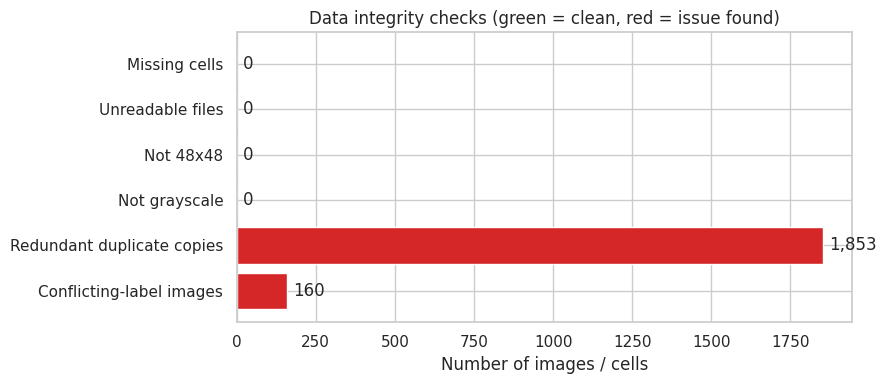

In [ ]:
# Visualizing the missing values
# An image dataset has no tabular gaps, so we visualise all integrity checks together instead of a null heat-map.
checks = pd.Series({
    'Missing cells': int(df.isnull().sum().sum()),
    'Unreadable files': len(corrupt_files),
    'Not 48x48': int(((df.height != 48) | (df.width != 48)).sum()),
    'Not grayscale': int((df.channels != 1).sum()),
    'Redundant duplicate copies': extra_copies,
    'Conflicting-label images': conflict_images,
})
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(checks.index, checks.values, color=['#2ca02c' if v == 0 else '#d62728' for v in checks.values])
for b, v in zip(bars, checks.values):
    ax.text(v + 20, b.get_y() + b.get_height() / 2, f'{v:,}', va='center')
ax.invert_yaxis()
ax.set(title='Data integrity checks (green = clean, red = issue found)', xlabel='Number of images / cells')
plt.tight_layout()
plt.show()

### What did you know about your dataset?

* The archive holds **71,774 files, but only 35,887 are unique images**: `images/images/` is an exact duplicate of `train/` + `validation/` and is ignored. The real dataset has **28,821 training and 7,066 validation images** in 7 emotion folders.
* Every image is a **48x48, single-channel grayscale** face crop. There are **no missing values and no unreadable files**.
* The dataset **is not clean**: there are **1,853 redundant copies** of identical images, **510 identical images that appear in both train and validation** (leakage) and **57 groups of identical images with conflicting labels** (160 images).
* The class sizes are very uneven (disgust is by far the smallest), and the pictures include different ages, poses, lighting and some occlusions, so the task is genuinely hard.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
print(list(df.columns))

['path', 'split', 'label', 'height', 'width', 'channels', 'brightness', 'contrast', 'min_px', 'max_px', 'sharpness', 'edge_density', 'grad_mag', 'left_right_asym', 'upper_lower', 'img_hash']


In [ ]:
# Dataset Describe
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
height,35887.0,48.00,0.00,48.00,48.00,48.00,48.00,48.00
width,35887.0,48.00,0.00,48.00,48.00,48.00,48.00,48.00
channels,35887.0,1.00,0.00,1.00,1.00,1.00,1.00,1.00
brightness,35887.0,129.38,33.52,0.00,106.78,129.54,152.64,247.95
contrast,35887.0,54.08,13.65,0.00,44.55,53.67,63.16,113.93
min_px,35887.0,7.73,12.95,0.00,0.00,1.00,11.00,205.00
max_px,35887.0,236.74,24.68,0.00,227.00,247.00,255.00,255.00
sharpness,35887.0,2384.97,1578.20,0.00,1453.01,2110.04,2945.67,31771.74
edge_density,35887.0,0.20,0.04,0.00,0.17,0.20,0.22,0.37
grad_mag,35887.0,122.06,30.61,0.00,101.39,120.45,140.42,373.01


### Variables Description

| Variable | Type | Description |
|---|---|---|
| `path` | text | File path of the image (identifier) |
| `split` | categorical | `train` or `validation` (provided split) |
| `label` | categorical (target) | Emotion class: angry, disgust, fear, happy, neutral, sad, surprise |
| `height`, `width`, `channels` | integer | Image geometry; all images are 48x48 with 1 channel |
| `brightness` | float | Mean grey level (0 = black, 255 = white) |
| `contrast` | float | Standard deviation of grey levels |
| `min_px`, `max_px` | integer | Darkest and brightest pixel: dynamic range used by the image |
| `sharpness` | float | Variance of the Laplacian; higher means more fine detail / sharper edges |
| `edge_density` | float | Fraction of pixels flagged as edges by the Canny detector |
| `grad_mag` | float | Mean Sobel gradient magnitude; overall strength of local intensity change |
| `left_right_asym` | float | Mean absolute difference between the left half and the mirrored right half |
| `upper_lower` | float | Upper-half brightness minus lower-half brightness |
| `img_hash` | text | MD5 hash of the pixels, used only to find duplicates |

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
display(df.nunique().rename('unique values').to_frame())
print('\nEmotion labels :', sorted(df['label'].unique()))
print('Splits         :', sorted(df['split'].unique()))

,unique values
path,35887
split,2
label,7
height,1
width,1
channels,1
brightness,32013
contrast,34034
min_px,132
max_px,175



Emotion labels : ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Splits         : ['train', 'validation']


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.
# Cleaning order matters: ambiguous labels first, then leakage, then plain duplicates, then degenerate images.
removal_log = {}

# 1) Identical images that carry different emotion labels are ambiguous - remove every copy.
conflict_hashes = df.groupby('img_hash')['label'].nunique().loc[lambda s: s > 1].index
mask = df['img_hash'].isin(conflict_hashes)
removal_log['Identical images with conflicting labels'] = int(mask.sum())
df = df[~mask]

# 2) Validation images that also exist in train leak training data into validation - drop the validation copy.
train_hashes = set(df.loc[df['split'] == 'train', 'img_hash'])
mask = (df['split'] == 'validation') & df['img_hash'].isin(train_hashes)
removal_log['Validation copies of training images (leakage)'] = int(mask.sum())
df = df[~mask]

# 3) Exact duplicates inside the same split - keep the first copy only.
mask = df.duplicated(['img_hash', 'split'], keep='first')
removal_log['Duplicate copies within a split'] = int(mask.sum())
df = df[~mask]

# 4) Almost blank frames (grey-level std < 5) carry no facial information.
mask = df['contrast'] < 5
removal_log['Near-blank images'] = int(mask.sum())
df = df[~mask].reset_index(drop=True)

summary = pd.Series(removal_log, name='images removed').to_frame()
summary.loc['TOTAL removed'] = summary['images removed'].sum()
display(summary)
print(f'\nBefore: {len(df_raw):,} images   After: {len(df):,} images   Removed: {len(df_raw) - len(df):,} ({(len(df_raw) - len(df)) / len(df_raw):.1%})')

before = df_raw.groupby(['label', 'split']).size().unstack()
after = df.groupby(['label', 'split']).size().unstack()
comparison = before.join(after, lsuffix='_before', rsuffix='_after')
comparison['train_change_%'] = ((comparison['train_after'] / comparison['train_before'] - 1) * 100).round(1)
display(comparison)
ratio = df['label'].value_counts()
print(f'Imbalance after cleaning: largest class (happy) is {ratio.max() / ratio.min():.1f}x the smallest (disgust).')

,images removed
Identical images with conflicting labels,160
Validation copies of training images (leakage),520
Duplicate copies within a split,1230
Near-blank images,2
TOTAL removed,1912



Before: 35,887 images   After: 33,975 images   Removed: 1,912 (5.3%)


split,train_before,validation_before,train_after,validation_after,train_change_%
label,,,,,
angry,3993,960,3824,893,-4.2
disgust,436,111,376,82,-13.8
fear,4103,1018,3888,914,-5.2
happy,7164,1825,7041,1752,-1.7
neutral,4982,1216,4863,1182,-2.4
sad,4938,1139,4829,1083,-2.2
surprise,3205,797,2680,568,-16.4


Imbalance after cleaning: largest class (happy) is 19.2x the smallest (disgust).


### What all manipulations have you done and insights you found?

**Manipulations (1,912 images, 5.3%, removed in total):**

1. **160** images belonging to 57 groups of identical pictures with *different* labels were removed (the true label is unknowable).
2. **520** validation images that are exact copies of training images were removed to stop validation scores being inflated by memorisation.
3. **1,230** remaining exact duplicates inside a split were reduced to a single copy.
4. **2** near-blank frames were removed.
5. The nested `images/images/` copy was ignored entirely.

**Insights:**

* The cleaned dataset has **33,975 images (27,501 train, 6,474 validation)**.
* Cleaning hit the minority classes hardest in relative terms: **surprise lost 16% of its training images** (3,205 to 2,680) and about 29% of its validation images, because duplication was concentrated there.
* The imbalance is now **19.2x** between happy (8,793) and disgust (458), so imbalance handling later in this notebook is unavoidable.
* All charts below use the **cleaned** data, except the duplication chart, which deliberately uses the raw data.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

Charts follow the **UBM** rule: **U**nivariate (charts 1-3), **B**ivariate (charts 4-11) and **M**ultivariate (charts 12-15). All charts use the cleaned `df` except chart 9, which deliberately uses the raw data to show the duplication problem. (A fuller set of 22 charts is in the companion EDA notebook.)

In [ ]:
# Helper used by the bivariate charts: tests whether a feature differs between emotions and how much it matters.
def kruskal_eta(feature):
    groups = [g[feature].values for _, g in df.groupby('label')]
    h, p = stats.kruskal(*groups)                                  # non-parametric: no normality assumption
    grand = df[feature].mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)    # between-emotion variance
    sst = ((df[feature] - grand) ** 2).sum()                       # total variance
    print(f'{feature}: Kruskal-Wallis H = {h:.1f}, p = {p:.2e}; emotion explains {ssb / sst:.2%} of the variance (eta-squared)')
    print(df.groupby('label')[feature].median().sort_values().round(2).to_string())

FEATURES = ['brightness', 'contrast', 'sharpness', 'edge_density', 'grad_mag', 'left_right_asym', 'upper_lower', 'min_px', 'max_px']

#### Chart - 1 - Class distribution (Univariate)

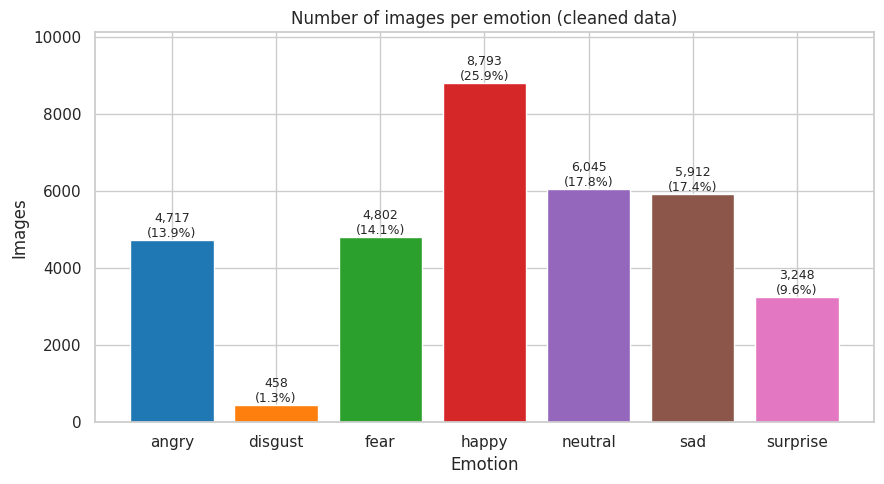

Imbalance ratio (largest / smallest): 19.2x


In [ ]:
# Chart - 1 visualization code
counts = df['label'].value_counts().reindex(EMOTIONS)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(counts.index, counts.values, color=[PALETTE[e] for e in counts.index])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 80, f'{v:,}\n({v / len(df):.1%})', ha='center', fontsize=9)
ax.set(title='Number of images per emotion (cleaned data)', xlabel='Emotion', ylabel='Images', ylim=(0, counts.max() * 1.15))
plt.tight_layout()
plt.show()
print(f'Imbalance ratio (largest / smallest): {counts.max() / counts.min():.1f}x')

##### 1. Why did you pick the specific chart?

A bar chart is the standard way to compare category sizes. Showing both the count and the percentage on each bar makes the imbalance visible immediately, and it is the first thing to check for any classification target.

##### 2. What is/are the insight(s) found from the chart?

* **Happy is the largest class (8,793 images, 25.9%)**, followed by neutral (6,045, 17.8%) and sad (5,912, 17.4%).
* **Disgust is tiny: 458 images, 1.3%**, which is **19.2x smaller than happy**. Surprise (3,248, 9.6%) is also under-represented; fear (4,802, 14.1%) and angry (4,717, 13.9%) sit in the middle.
* Happy, neutral and sad together make up about 61% of the data.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing the imbalance early lets us plan class-weighted loss, oversampling or targeted augmentation, and choose macro-F1 and per-class recall instead of plain accuracy. This protects rare but valuable signals such as disgust and fear in mental-health or customer-service use cases.

**Negative if ignored:** a model could reach roughly 60% accuracy just by favouring happy/neutral/sad while almost never predicting disgust. That would look good in a report but fail exactly where emotion detection matters (e.g. detecting distress).

#### Chart - 2 - Brightness distribution (Univariate)

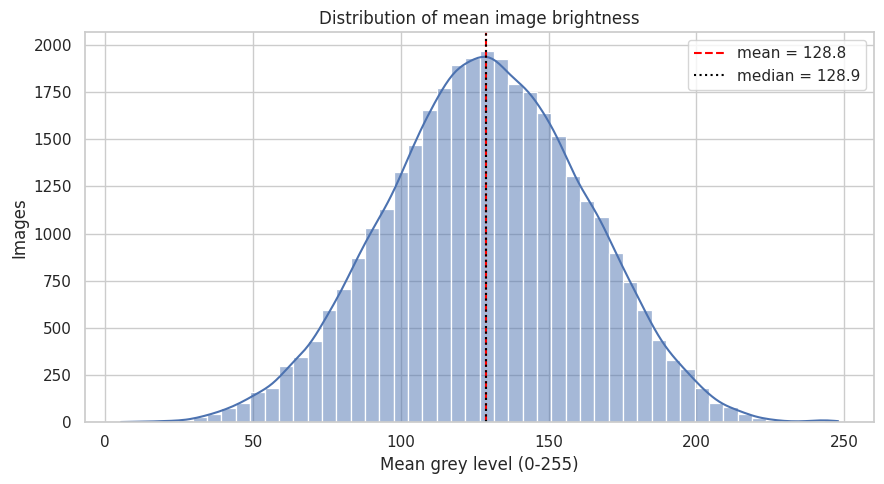

count    33975.00
mean       128.83
std         33.42
min          5.35
25%        106.16
50%        128.88
75%        152.01
max        247.95
skewness = -0.04;  images darker than 30: 29,  brighter than 220: 55


In [ ]:
# Chart - 3 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['brightness'], bins=50, kde=True, color='#4c72b0', ax=ax)
ax.axvline(df['brightness'].mean(), color='red', ls='--', label=f"mean = {df['brightness'].mean():.1f}")
ax.axvline(df['brightness'].median(), color='black', ls=':', label=f"median = {df['brightness'].median():.1f}")
ax.set(title='Distribution of mean image brightness', xlabel='Mean grey level (0-255)', ylabel='Images')
ax.legend()
plt.tight_layout()
plt.show()
print(df['brightness'].describe().round(2).to_string())
print(f"skewness = {df['brightness'].skew():.2f};  images darker than 30: {(df['brightness'] < 30).sum()},  brighter than 220: {(df['brightness'] > 220).sum()}")

##### 1. Why did you pick the specific chart?

A histogram with a density curve shows the shape, centre and spread of a single numeric variable, which tells us whether lighting is consistent across the dataset.

##### 2. What is/are the insight(s) found from the chart?

* Brightness is **almost perfectly symmetric (skewness about -0.04)** with mean about 128.8 and standard deviation about 33.4.
* The middle half of images lies between roughly **106 and 152**, but the full range is very wide (**5 to 248**): a few images are almost black or almost white (29 darker than 30, 55 brighter than 220).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** lighting varies a lot, so brightness/contrast augmentation will help the CNN become robust to real-world conditions such as webcams, dim rooms and strong sunlight.

**Negative:** the extremes (very dark or washed-out faces) contain little expression information and may add noise. They are rare (about 0.25% of images), so they are not removed, but they are a likely source of errors in deployment.

#### Chart - 3 - Contrast distribution (Univariate)

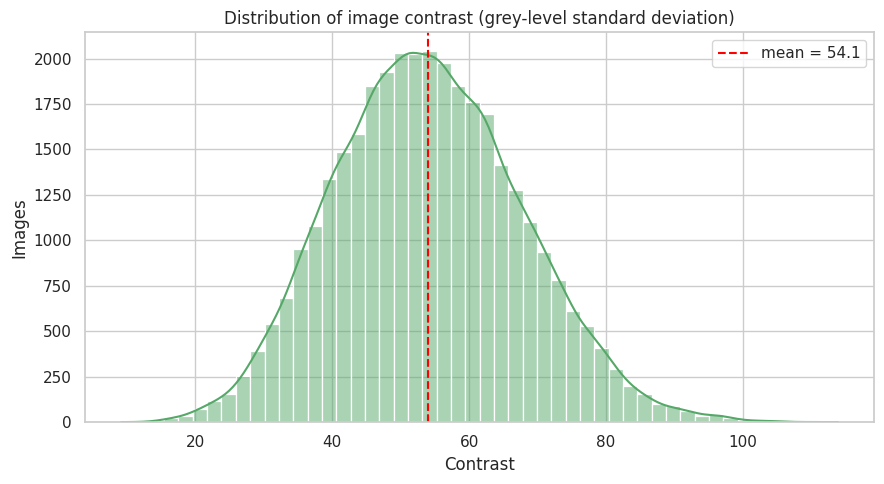

count    33975.00
mean        54.06
std         13.64
min          9.14
25%         44.50
50%         53.62
75%         63.13
max        113.93
skewness = 0.21;  images with contrast below 20: 82


In [ ]:
# Chart - 4 visualization code
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(df['contrast'], bins=50, kde=True, color='#55a868', ax=ax)
ax.axvline(df['contrast'].mean(), color='red', ls='--', label=f"mean = {df['contrast'].mean():.1f}")
ax.set(title='Distribution of image contrast (grey-level standard deviation)', xlabel='Contrast', ylabel='Images')
ax.legend()
plt.tight_layout()
plt.show()
print(df['contrast'].describe().round(2).to_string())
print(f"skewness = {df['contrast'].skew():.2f};  images with contrast below 20: {(df['contrast'] < 20).sum()}")

##### 1. Why did you pick the specific chart?

Contrast is a second, independent view of image quality (brightness only tells us the average level). A histogram again shows shape and outliers.

##### 2. What is/are the insight(s) found from the chart?

* Contrast is roughly bell-shaped with a mild right skew (**skewness 0.21**), mean about **54.1**, standard deviation about **13.6**, range about **9 to 114**.
* Only **82 images (0.24%)** have contrast below 20, i.e. look flat and washed out.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** most images have usable contrast, so facial structure (eyes, brows, mouth) is visible; standardising each image (subtract its mean, divide by its standard deviation) is a safe preprocessing step that removes this nuisance variation.

**Negative:** the few flat, low-contrast images are hard for any model; they are too few to hurt training, but they will be misclassified more often at inference time.

#### Chart - 4 - Brightness by emotion (Bivariate: numerical vs categorical)

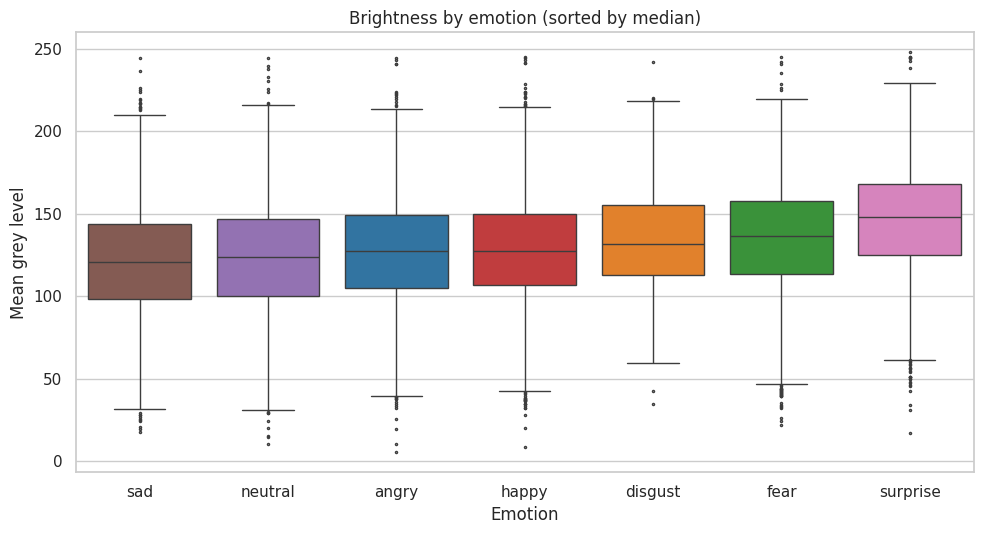

brightness: Kruskal-Wallis H = 1489.5, p = 0.00e+00; emotion explains 4.41% of the variance (eta-squared)
label
sad         120.98
neutral     123.75
angry       127.37
happy       127.58
disgust     131.52
fear        136.72
surprise    147.78


In [ ]:
# Chart - 7 visualization code
order = df.groupby('label')['brightness'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df, x='label', y='brightness', order=order, palette=PALETTE, fliersize=1.5, ax=ax)
ax.set(title='Brightness by emotion (sorted by median)', xlabel='Emotion', ylabel='Mean grey level')
plt.tight_layout()
plt.show()
kruskal_eta('brightness')

##### 1. Why did you pick the specific chart?

A box plot compares the median, spread and outliers of a numeric variable across several categories at once, and sorting by median makes the ranking easy to read.

##### 2. What is/are the insight(s) found from the chart?

* Median brightness ranks **sad (121.0) < neutral (123.8) < angry (127.4) ~ happy (127.6) < disgust (131.5) < fear (136.7) < surprise (147.8)**.
* Surprise images are about **27 grey levels brighter than sad** images. A plausible reason is that wide-open eyes and mouths expose bright sclera and teeth, but this is a hypothesis, not something the chart proves.
* The differences are statistically significant (Kruskal-Wallis p < 0.001) but **emotion explains only 4.4% of brightness variance**: the spread within each emotion (std about 32-33) is far larger than the gaps between medians.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** brightness augmentation is clearly justified, and it is the strongest simple signal in the data.

**Negative / risk:** because surprise is brighter on average, a model could learn a **shortcut (bright face = surprise)** that fails under different lighting. This would hurt real-world accuracy. Brightness jitter, per-image normalisation and checking per-class errors on dark/bright subsets mitigate it.

#### Chart - 5 - Contrast by emotion (Bivariate: numerical vs categorical)

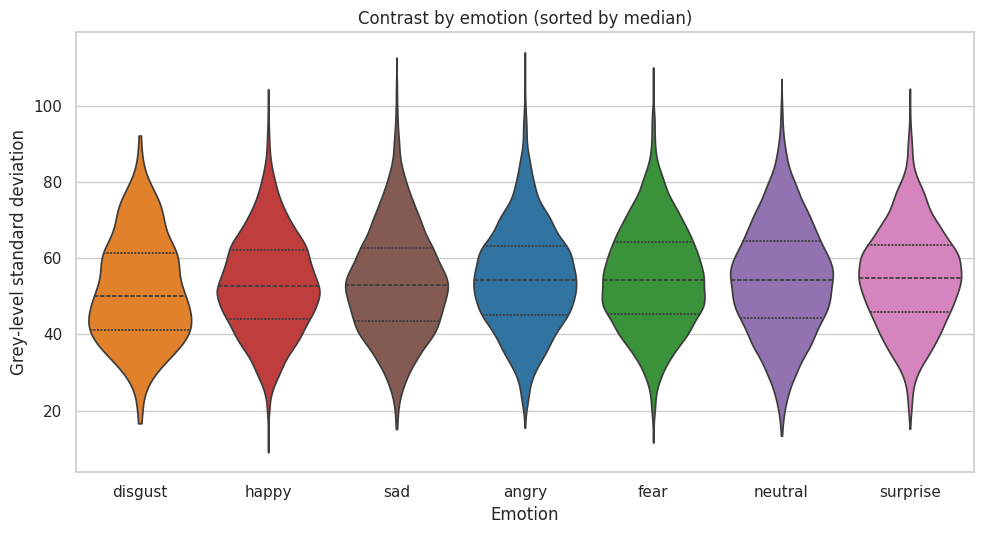

contrast: Kruskal-Wallis H = 106.9, p = 8.88e-21; emotion explains 0.29% of the variance (eta-squared)
label
disgust     50.02
happy       52.63
sad         52.84
angry       54.19
fear        54.33
neutral     54.35
surprise    54.87


In [ ]:
# Chart - 8 visualization code
order = df.groupby('label')['contrast'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.violinplot(data=df, x='label', y='contrast', order=order, palette=PALETTE, cut=0, inner='quartile', ax=ax)
ax.set(title='Contrast by emotion (sorted by median)', xlabel='Emotion', ylabel='Grey-level standard deviation')
plt.tight_layout()
plt.show()
kruskal_eta('contrast')

##### 1. Why did you pick the specific chart?

A violin plot shows the full distribution shape for each class (not just quartiles), which helps judge whether the distributions really differ or just have different tails.

##### 2. What is/are the insight(s) found from the chart?

* Median contrast only ranges from **about 50.0 (disgust) to 54.9 (surprise)**; the violins have almost identical shapes.
* The Kruskal-Wallis test is significant (p about 1e-20) only because of the large sample, while **emotion explains just 0.3% of contrast variance**. This is a clear example of **statistical vs practical significance**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** contrast carries almost no emotion information, so normalising it away (per-image standardisation) is safe and removes nuisance variation without losing signal.

**Negative:** none for the model, but engineering contrast as a feature would waste effort; no business value is gained from it.

#### Chart - 6 - Class proportions in train vs validation (Bivariate: categorical vs categorical)

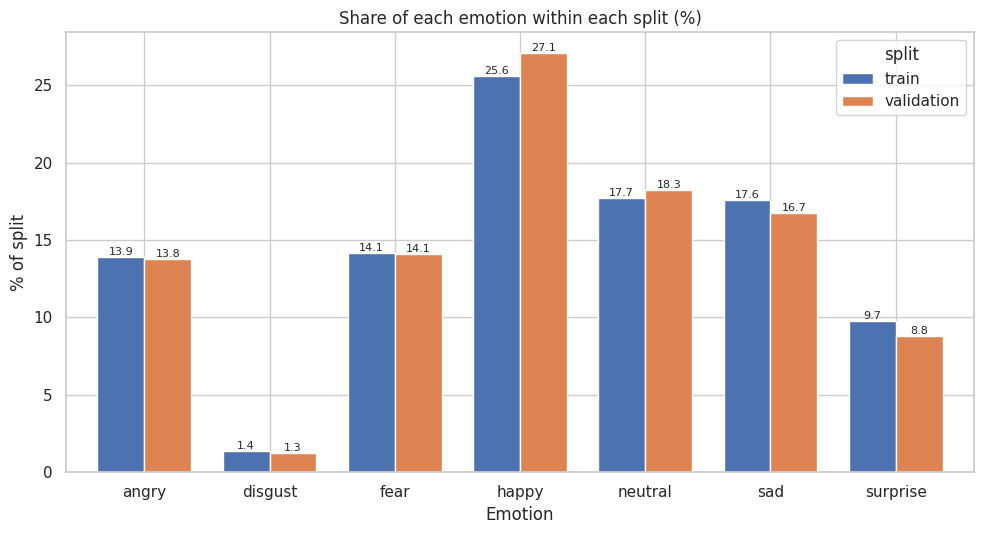

Largest absolute difference between splits: 1.46 percentage points


In [ ]:
# Chart - 11 visualization code
share = (df.groupby('split')['label'].value_counts(normalize=True).unstack(0).reindex(EMOTIONS) * 100)
ax = share[['train', 'validation']].plot.bar(figsize=(10, 5.5), color=['#4c72b0', '#dd8452'], width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=8)
ax.set(title='Share of each emotion within each split (%)', xlabel='Emotion', ylabel='% of split')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
print('Largest absolute difference between splits: %.2f percentage points' % (share['train'] - share['validation']).abs().max())

##### 1. Why did you pick the specific chart?

A grouped bar chart compares two categorical distributions side by side, which is exactly what is needed to check whether the validation set is representative of the training set.

##### 2. What is/are the insight(s) found from the chart?

* The splits are **well stratified**: every class share differs by **at most about 1.5 percentage points** (largest gap: happy 25.6% in train vs 27.1% in validation); disgust is 1.4% vs 1.3%.
* Both splits inherit the same imbalance: **happy + neutral + sad make up about 62% of validation**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** validation metrics are comparable with training metrics and a model will not be judged on a different mix of emotions.

**Negative:** because validation is also dominated by three classes, overall accuracy is dominated by them as well and will hide weak performance on disgust, surprise and fear. Macro-averaged metrics are required.

#### Chart - 7 - Left-right asymmetry by emotion (Bivariate: numerical vs categorical)

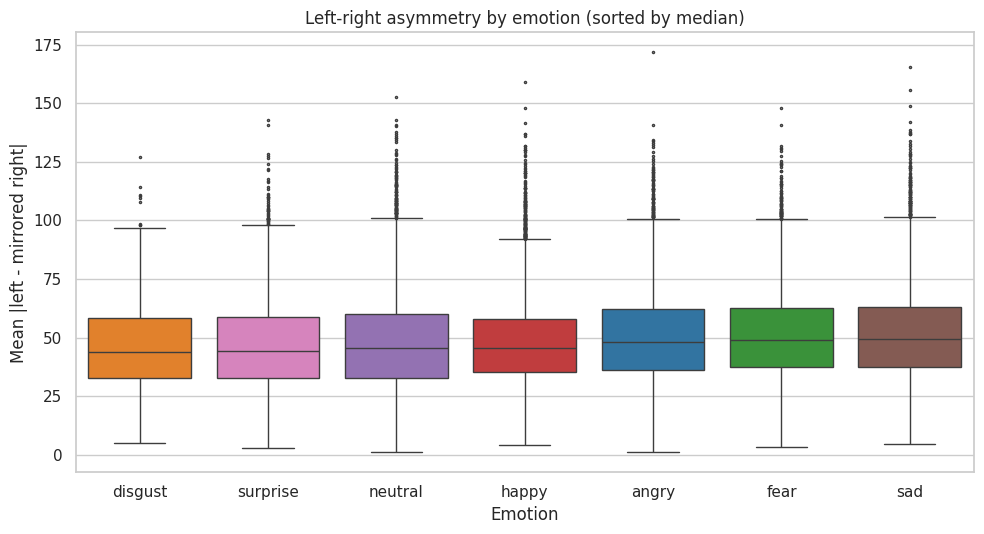

left_right_asym: Kruskal-Wallis H = 309.3, p = 8.49e-64; emotion explains 0.84% of the variance (eta-squared)
label
disgust     44.01
surprise    44.50
neutral     45.49
happy       45.50
angry       48.12
fear        49.15
sad         49.34
correlation of asymmetry with contrast: 0.63


In [ ]:
# Chart - 12 visualization code
order = df.groupby('label')['left_right_asym'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df, x='label', y='left_right_asym', order=order, palette=PALETTE, fliersize=1.5, ax=ax)
ax.set(title='Left-right asymmetry by emotion (sorted by median)', xlabel='Emotion', ylabel='Mean |left - mirrored right|')
plt.tight_layout()
plt.show()
kruskal_eta('left_right_asym')
print(f"correlation of asymmetry with contrast: {df['left_right_asym'].corr(df['contrast']):.2f}")

##### 1. Why did you pick the specific chart?

Asymmetry tests an anatomical idea (are some expressions less symmetric?) and also tells us whether horizontal-flip augmentation is realistic. A box plot compares the classes.

##### 2. What is/are the insight(s) found from the chart?

* Median asymmetry is about **44.0 (disgust), 44.5 (surprise), 45.5 (neutral, happy), 48.1 (angry), 49.2 (fear), 49.3 (sad)**; emotion explains only **0.8%** of the variance.
* Faces are far from symmetric in pixel terms (typical difference about 47 grey levels), and asymmetry is strongly tied to image contrast (**r = 0.63**), so it mostly reflects **pose and lighting rather than the expression itself**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** because real faces vary in pose and lighting anyway, **horizontal-flip augmentation is label-preserving and realistic**, effectively doubling the variety of every class at no cost.

**Negative:** asymmetry is not a useful emotion feature, and a model that leans on lighting direction would generalise poorly; flips and brightness jitter help reduce that dependency.

#### Chart - 8 - Upper vs lower face brightness by emotion (Bivariate: numerical vs categorical)

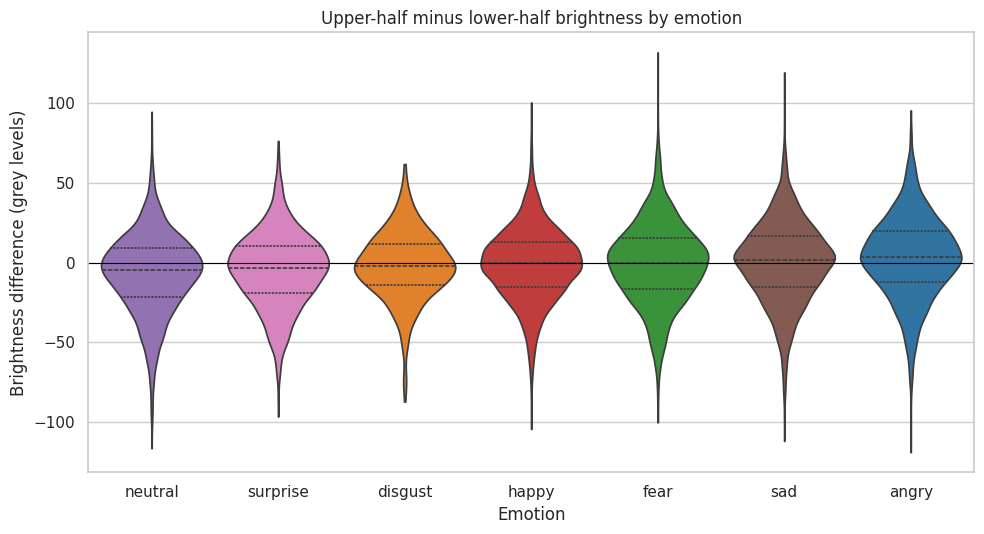

upper_lower: Kruskal-Wallis H = 511.4, p = 3.01e-107; emotion explains 1.57% of the variance (eta-squared)
label
neutral    -4.69
surprise   -3.15
disgust    -1.87
happy      -0.42
fear        0.14
sad         1.54
angry       3.78


In [ ]:
# Chart - 13 visualization code
order = df.groupby('label')['upper_lower'].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.violinplot(data=df, x='label', y='upper_lower', order=order, palette=PALETTE, cut=0, inner='quartile', ax=ax)
ax.axhline(0, color='black', lw=0.8)
ax.set(title='Upper-half minus lower-half brightness by emotion', xlabel='Emotion', ylabel='Brightness difference (grey levels)')
plt.tight_layout()
plt.show()
kruskal_eta('upper_lower')

##### 1. Why did you pick the specific chart?

Expressions act on different facial regions (brows and eyes on top, mouth at the bottom). Comparing the brightness of the top and bottom halves is a simple way to see if regional differences exist; a violin plot shows the full spread around zero.

##### 2. What is/are the insight(s) found from the chart?

* Medians run from **+3.8 (angry) and +1.5 (sad) through about 0 (fear, happy) to -1.9 (disgust), -3.2 (surprise) and -4.7 (neutral)**: an 8.5 grey-level gap between angry and neutral.
* Emotion explains **1.6%** of the variance, the highest among the non-brightness features, but the spread (std about 25) dwarfs the gaps. A possible reading is that frowning brows shade the upper face while open mouths with visible teeth brighten the lower face, but lighting direction is a competing explanation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it supports the idea that emotion information is **regional**: the eyes/brow and mouth areas should be preserved, so aggressive cropping or heavy random erasing should be avoided.

**Negative:** top-down lighting is a confounder, and without lighting augmentation the model might use shading instead of expression.

#### Chart - 9 - Share of duplicated images by emotion, raw data (Bivariate: categorical vs categorical)

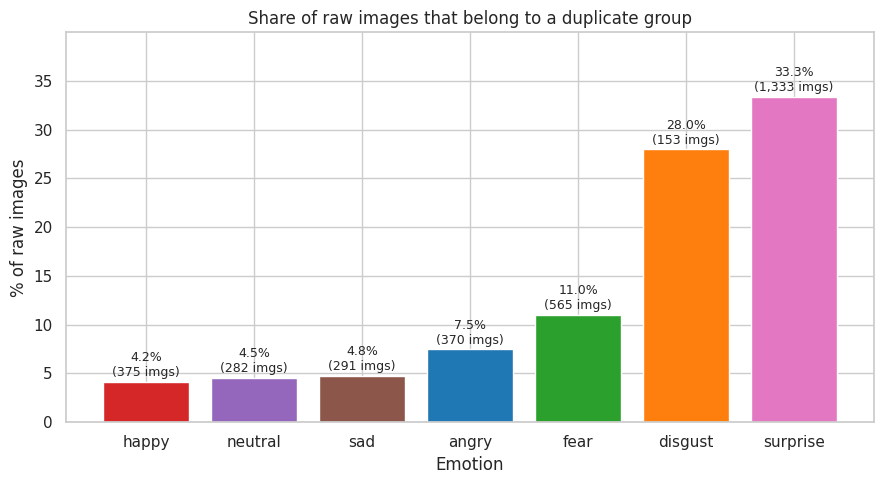

In [ ]:
# Chart - 14 visualization code (uses the RAW data before cleaning)
in_dup_group = df_raw.duplicated('img_hash', keep=False)
dup_pct = (in_dup_group.groupby(df_raw['label']).mean() * 100).reindex(EMOTIONS).sort_values()
dup_n = in_dup_group.groupby(df_raw['label']).sum().reindex(dup_pct.index)
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(dup_pct.index, dup_pct.values, color=[PALETTE[e] for e in dup_pct.index])
for b, p, n in zip(bars, dup_pct.values, dup_n.values):
    ax.text(b.get_x() + b.get_width() / 2, p + 0.6, f'{p:.1f}%\n({n:,} imgs)', ha='center', fontsize=9)
ax.set(title='Share of raw images that belong to a duplicate group', xlabel='Emotion', ylabel='% of raw images', ylim=(0, dup_pct.max() * 1.2))
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of percentages (not counts) is needed because the classes have different sizes; a raw count would hide that duplication is a much bigger problem for small classes.

##### 2. What is/are the insight(s) found from the chart?

* **33.3% of surprise images and 28.0% of disgust images belong to duplicate groups**, versus 11.0% for fear, 7.5% for angry and only about 4.2-4.8% for happy, neutral and sad.
* Duplication is **concentrated in exactly the classes that are already under-represented**, so a model trained on the raw data would see surprise and disgust inflated by repeated copies.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** removing duplicates prevents memorisation and inflated validation scores, so reported accuracy will reflect real performance; this is the most important data-quality fix in the project.

**Negative:** after cleaning, surprise loses about 16% of its training images and the class imbalance widens. This has to be compensated with augmentation or class weighting, otherwise cleaning would slightly hurt the minority classes.

#### Chart - 10 - Sample images per emotion (Bivariate: image vs categorical)

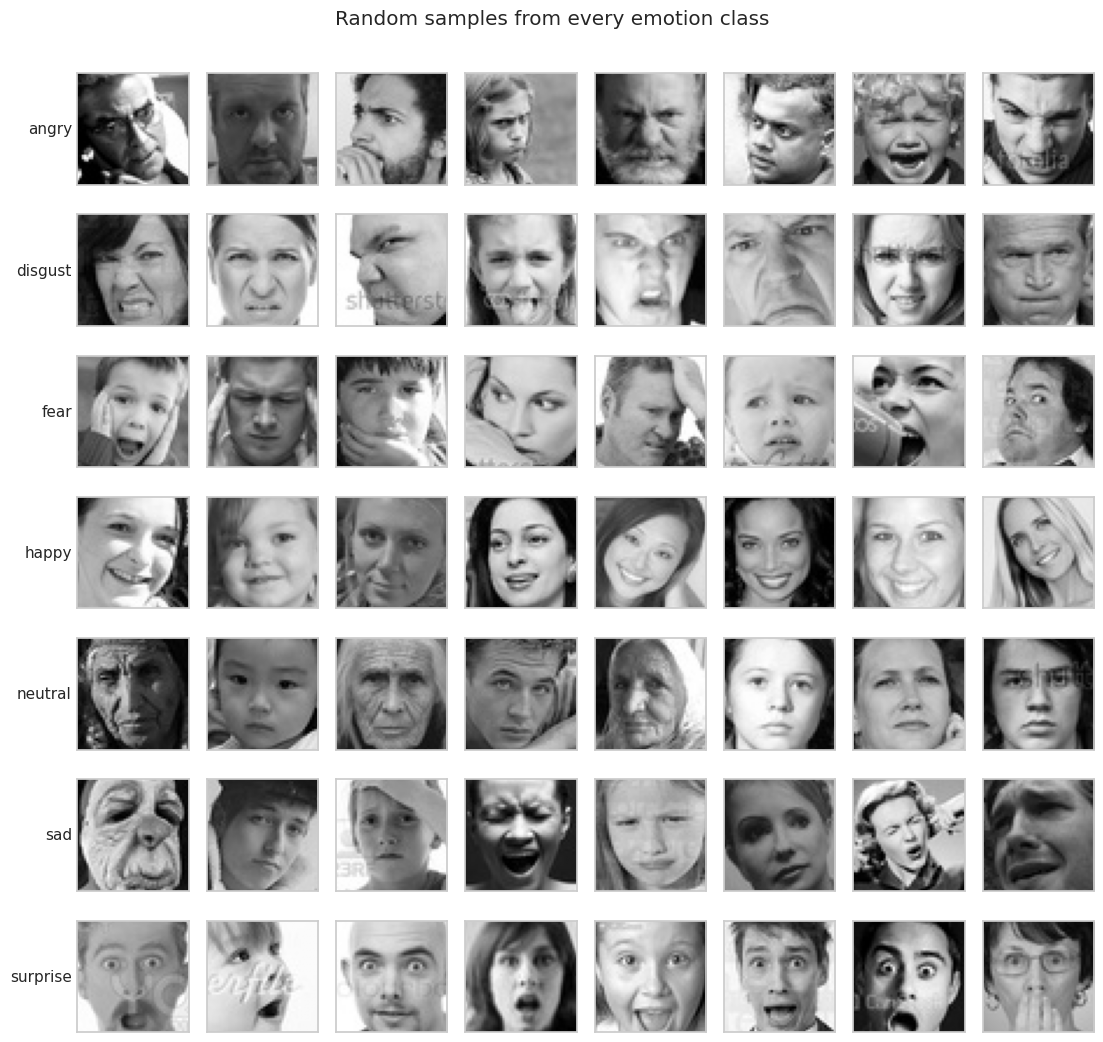

In [ ]:
# Chart - 15 visualization code
rng = np.random.RandomState(RANDOM_STATE)
n_cols = 8
fig, axes = plt.subplots(len(EMOTIONS), n_cols, figsize=(n_cols * 1.4, len(EMOTIONS) * 1.5))
for i, emo in enumerate(EMOTIONS):
    paths = df.loc[df['label'] == emo, 'path'].sample(n_cols, random_state=RANDOM_STATE).values
    for j, p in enumerate(paths):
        axes[i, j].imshow(cv2.imread(p, cv2.IMREAD_GRAYSCALE), cmap='gray', vmin=0, vmax=255)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        if j == 0:
            axes[i, j].set_ylabel(emo, rotation=0, ha='right', va='center', fontsize=11)
fig.suptitle('Random samples from every emotion class', y=1.0)
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Statistics cannot show label noise, occlusion or pose variation, so looking at real examples is an essential qualitative check before modelling.

##### 2. What is/are the insight(s) found from the chart?

* Images are tightly cropped, roughly centred faces of **all ages (babies to older adults)**.
* Real-world difficulties are visible: **profile and tilted views, glasses, hands covering the face, watermarks, a drawing among photographs, and very dark or very bright frames**.
* Some labels look **ambiguous** (for example expressions that could be read as angry, fear or surprise), which suggests an accuracy ceiling below 100% caused by label noise.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the diversity of the data is good for building a robust model, and the examples justify rotation, flip and brightness augmentation.

**Negative:** label noise and occlusion put a ceiling on achievable accuracy, and non-photographic items such as drawings and watermarks add noise; business users should be told that expected accuracy is limited, especially for fear vs surprise and sad vs neutral.

#### Chart - 11 - Average face per emotion (Bivariate: image vs categorical)

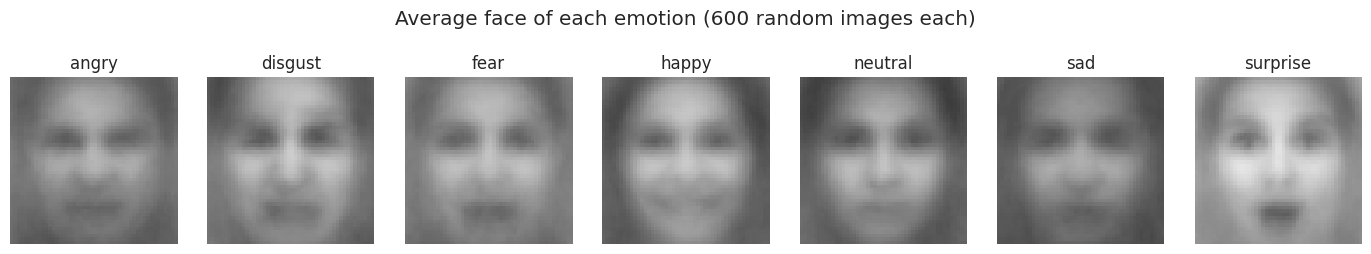

Mean absolute pixel difference from the neutral average face:
neutral      0.0
happy        6.6
sad          6.6
angry        7.6
disgust      9.8
fear        10.6
surprise    22.0


In [ ]:
# Chart - 16 visualization code
# Load up to 600 images per emotion once; they are reused by charts 17 and 22.
sample_imgs = {}
for emo in EMOTIONS:
    paths = df.loc[df['label'] == emo, 'path'].sample(min(600, (df['label'] == emo).sum()), random_state=RANDOM_STATE)
    sample_imgs[emo] = np.stack([cv2.imread(p, cv2.IMREAD_GRAYSCALE) for p in paths]).astype(np.float32)
mean_faces = {emo: arr.mean(axis=0) for emo, arr in sample_imgs.items()}

fig, axes = plt.subplots(1, 7, figsize=(14, 2.4))
for ax, emo in zip(axes, EMOTIONS):
    ax.imshow(mean_faces[emo], cmap='gray', vmin=60, vmax=200)
    ax.set_title(emo); ax.axis('off')
fig.suptitle('Average face of each emotion (600 random images each)', y=1.05)
plt.tight_layout()
plt.show()
neutral = mean_faces['neutral']
print('Mean absolute pixel difference from the neutral average face:')
print(pd.Series({e: np.abs(mean_faces[e] - neutral).mean() for e in EMOTIONS}).round(1).sort_values().to_string())

##### 1. Why did you pick the specific chart?

Averaging many faces cancels individual identity and shows what is systematically common to an emotion, which is a direct way to see where in the face the expression information lives.

##### 2. What is/are the insight(s) found from the chart?

* The average faces are **blurry, centred faces with eyes, nose and mouth roughly aligned**, so the crops are reasonably consistent, but individual variation is much larger than expression differences.
* **Surprise is the only average face that clearly stands out**: it is much brighter and shows a dark, open mouth. Measured against the neutral average it differs by about **22.0 grey levels**, then fear (10.6), disgust (9.8), angry (7.6), happy (6.6) and sad (6.6).
* Part of the surprise difference is simply its higher overall brightness (see chart 4).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the subtle differences confirm that a CNN must learn **fine local patterns** in the eye, brow and mouth regions rather than global appearance, which supports deeper models and transfer learning over simple classifiers.

**Negative:** since the average faces of angry, sad and happy are within about 6.6-7.6 grey levels of neutral, these classes are likely to be confused with each other and with neutral, and the model will need good capacity and augmentation to separate them.

#### Chart - 12 - Correlation heatmap of image features (Multivariate)

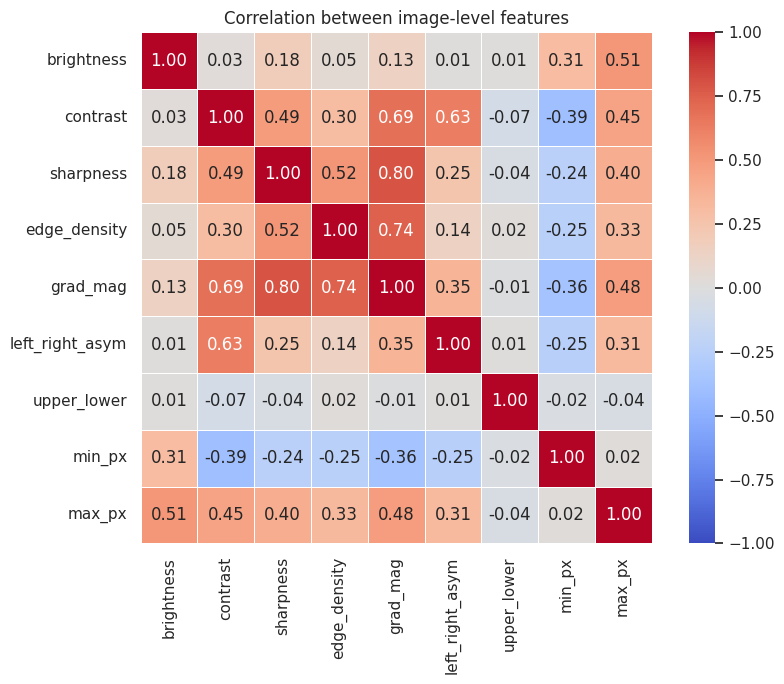

Strongest correlations:
sharpness     grad_mag           0.80
edge_density  grad_mag           0.74
contrast      grad_mag           0.69
              left_right_asym    0.63
sharpness     edge_density       0.52
brightness    max_px             0.51


In [ ]:
# Chart - 19 visualization code (Correlation Heatmap)
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlation between image-level features')
plt.tight_layout()
plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print('Strongest correlations:')
print(pairs.head(6).round(2).to_string())

##### 1. Why did you pick the specific chart?

A correlation heatmap summarises all pairwise linear relationships in one picture and is the standard tool for spotting redundant features.

##### 2. What is/are the insight(s) found from the chart?

* **Gradient magnitude, sharpness and edge density are strongly related**: grad_mag-sharpness r = 0.80, grad_mag-edge_density r = 0.74, sharpness-edge_density r = 0.52; contrast-grad_mag is 0.69 and contrast-asymmetry is 0.63.
* **Brightness is almost independent of contrast (r = 0.03)** and the upper-lower difference is uncorrelated with everything (|r| <= 0.07).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it guides feature selection: if hand-crafted features are used, keep **brightness, contrast, edge density, upper-lower difference** and drop grad_mag (redundant with sharpness), which reduces multicollinearity and keeps the feature set small and interpretable.

**Negative:** these features are weak predictors (charts 4-8), so even a well-selected set will not match a CNN; they are useful for explanation and data auditing, not as the main model input.

#### Chart - 13 - Pair plot of key features by emotion (Multivariate)

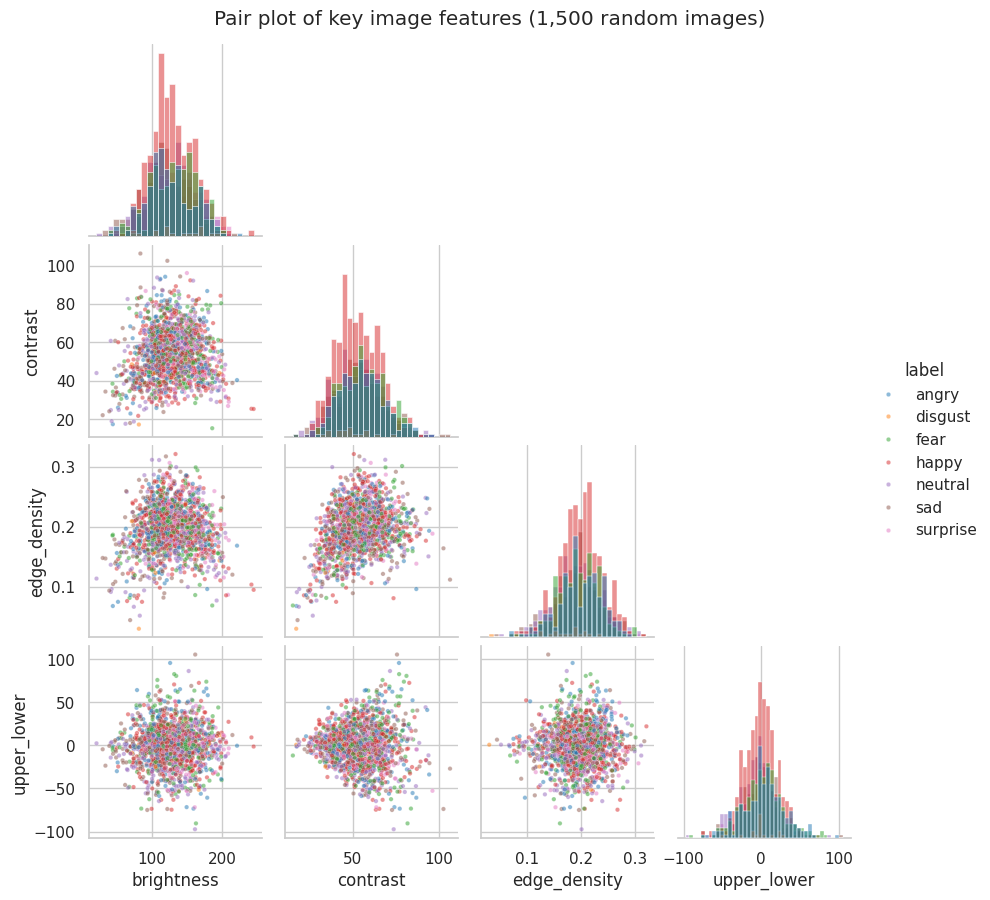

In [ ]:
# Chart - 20 visualization code (Pair Plot)
pp_df = df.sample(1500, random_state=RANDOM_STATE)
g = sns.pairplot(pp_df, vars=['brightness', 'contrast', 'edge_density', 'upper_lower'], hue='label', hue_order=EMOTIONS,
                 palette=PALETTE, diag_kind='hist', plot_kws=dict(s=10, alpha=0.5), height=2.2, corner=True)
g.fig.suptitle('Pair plot of key image features (1,500 random images)', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every two-way relationship between features and, with colour by emotion, reveals at a glance whether the classes form separate clusters.

##### 2. What is/are the insight(s) found from the chart?

* The seven colours **overlap heavily in every panel**; no pair of simple features separates the emotions.
* The only visible tendency is that surprise (high brightness) is shifted slightly to the right in the brightness panels; contrast and brightness show no relationship, as chart 12 predicted.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it provides clear evidence for the modelling decision: classical models on global statistics would perform poorly, so a **CNN on raw pixels** is justified.

**Negative:** it also warns that the classes are hard to separate even for sophisticated models; stakeholders should expect confusion between visually similar emotions.

#### Chart - 14 - PCA projection of raw pixels (Multivariate)

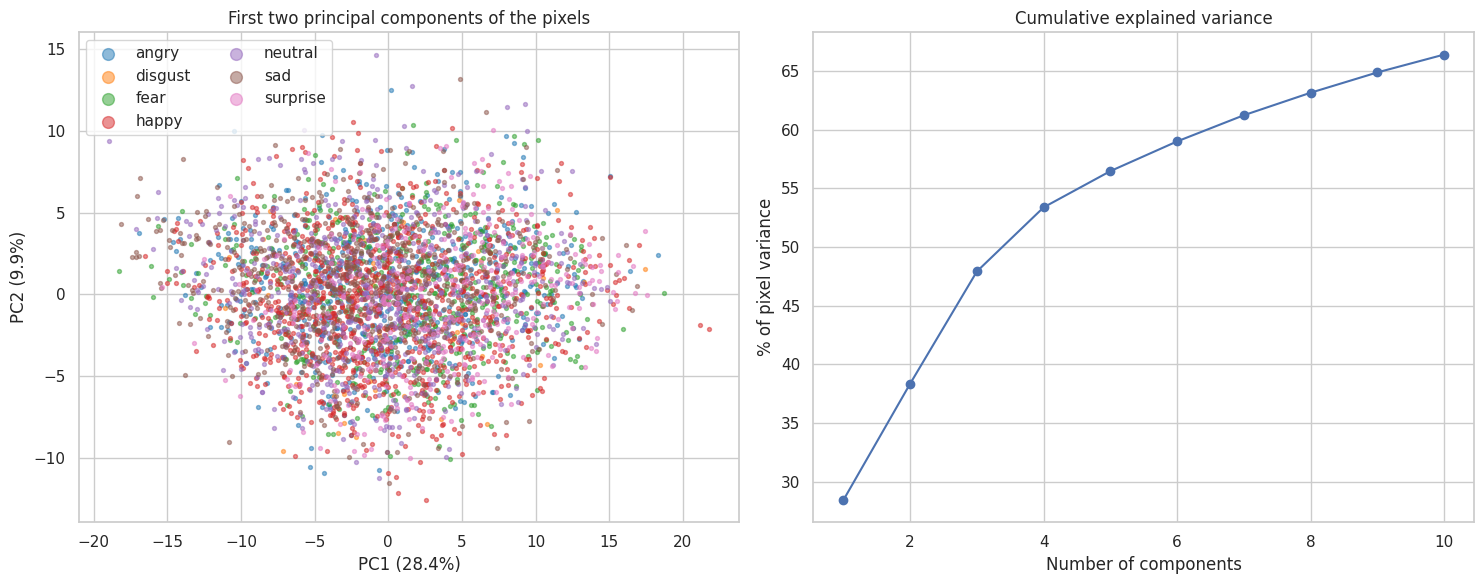

Explained variance of the first 10 components: [28.4 38.4 47.9 53.4 56.5 59.  61.2 63.1 64.9 66.4]
PC1 vs brightness correlation: 0.993
PC2 vs contrast correlation  : -0.290


In [ ]:
# Chart - 21 visualization code
pca_df = df.sample(4000, random_state=RANDOM_STATE)
X = np.stack([cv2.imread(p, cv2.IMREAD_GRAYSCALE).ravel() for p in pca_df['path']]).astype(np.float32) / 255.0
pca = PCA(n_components=10, random_state=RANDOM_STATE).fit(X)
Z = pca.transform(X)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for emo in EMOTIONS:
    m = (pca_df['label'] == emo).values
    axes[0].scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, label=emo, color=PALETTE[emo])
axes[0].set(title='First two principal components of the pixels', xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
axes[0].legend(markerscale=3, ncol=2)
axes[1].plot(range(1, 11), np.cumsum(pca.explained_variance_ratio_) * 100, marker='o')
axes[1].set(title='Cumulative explained variance', xlabel='Number of components', ylabel='% of pixel variance')
plt.tight_layout()
plt.show()
print('Explained variance of the first 10 components:', (np.cumsum(pca.explained_variance_ratio_) * 100).round(1))
print(f"PC1 vs brightness correlation: {np.corrcoef(Z[:, 0], pca_df['brightness'])[0, 1]:.3f}")
print(f"PC2 vs contrast correlation  : {np.corrcoef(Z[:, 1], pca_df['contrast'])[0, 1]:.3f}")

##### 1. Why did you pick the specific chart?

PCA compresses the 2,304 pixels per image into a few directions of maximum variance. Plotting the first two shows whether emotions form natural clusters in pixel space, and the cumulative curve shows how compressible the data is.

##### 2. What is/are the insight(s) found from the chart?

* **PC1 explains 28.4% and PC2 10.0% of the variance; ten components reach only about 66%**, so the pixel data is not low-dimensional.
* **PC1 is essentially global brightness (r = 0.99 with mean brightness)**: the biggest source of variation in the images is lighting, not expression. The emotion colours are thoroughly mixed in the PC1-PC2 plane.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it justifies keeping the full image as input (aggressive dimensionality reduction would discard information) and reinforces the need for **brightness normalisation and augmentation**, since lighting dominates the pixel variance.

**Negative:** emotion is not the dominant source of variation, so unsupervised approaches (clustering, linear methods on raw pixels) will perform poorly; supervised deep learning is required.

#### Chart - 15 - Difference of each average face from neutral (Multivariate)

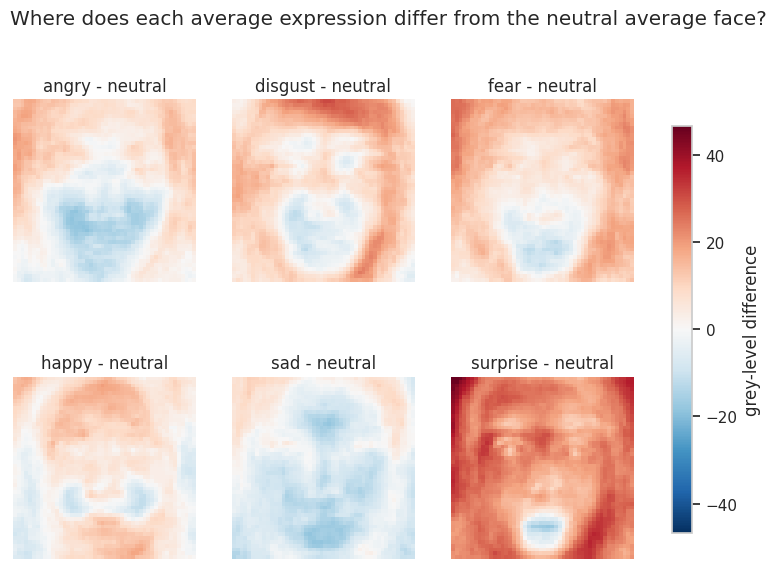

angry     mean diff =    2.0   upper-half mean =    7.5   lower-half mean =   -3.5
disgust   mean diff =    8.4   upper-half mean =   11.3   lower-half mean =    5.4
fear      mean diff =    9.4   upper-half mean =   12.8   lower-half mean =    5.9
happy     mean diff =    4.7   upper-half mean =    7.3   lower-half mean =    2.1
sad       mean diff =   -4.6   upper-half mean =   -1.1   lower-half mean =   -8.0
surprise  mean diff =   21.5   upper-half mean =   23.5   lower-half mean =   19.5


In [ ]:
# Chart - 22 visualization code
others = [e for e in EMOTIONS if e != 'neutral']
diffs = {e: mean_faces[e] - mean_faces['neutral'] for e in others}
vmax = max(np.abs(d).max() for d in diffs.values())
fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))
for ax, emo in zip(axes.ravel(), others):
    im = ax.imshow(diffs[emo], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(f'{emo} - neutral'); ax.axis('off')
fig.colorbar(im, ax=axes, shrink=0.8, label='grey-level difference')
fig.suptitle('Where does each average expression differ from the neutral average face?')
plt.show()
for emo in others:
    d = diffs[emo]
    print(f'{emo:9s} mean diff = {d.mean():6.1f}   upper-half mean = {d[:24].mean():6.1f}   lower-half mean = {d[24:].mean():6.1f}')

##### 1. Why did you pick the specific chart?

Subtracting the neutral average face turns a visual comparison into a map of **where** each expression changes the picture, combining spatial (x, y) and class information, which is why it is a multivariate view.

##### 2. What is/are the insight(s) found from the chart?

* **Surprise shows a strong, face-wide brightening (mean +21.5 grey levels) with a dark patch at the open mouth**; fear (+9.4) and disgust (+8.4) are moderately brighter, angry (+2.0) and happy (+4.7) are close to neutral, and **sad is darker overall (-4.6)**.
* The most consistent local pattern is a **darker mouth and lower-centre region than neutral for angry, disgust, fear, sad and surprise**. Bright patches near the forehead, hair and borders (notably disgust and surprise) look more like lighting or sampling effects, especially since disgust has only 458 images.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it shows that the mouth and lower-centre region carries consistent expression information, so consistent face alignment is valuable, and class activation maps (Grad-CAM) later in this notebook can be checked against this expectation to confirm the model looks at sensible regions.

**Negative:** because part of the signal is global brightness (especially for surprise), a model could rely on it instead of facial muscle movement; brightness augmentation and normalisation are needed to force it to learn expression cues.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Three statements follow directly from the charts. All use a significance level of **alpha = 0.05**. Because the dataset is large (about 34,000 images), even tiny differences become 'significant', so every test is paired with an **effect size** to judge practical importance.

1. **Brightness differs between emotions** (charts 2 and 4).
2. **Surprise images are brighter than sad images** (charts 4 and 11).
3. **Being a duplicate depends on the emotion** (chart 9).

### Hypothetical Statement - 1: Typical image brightness differs between emotions

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** the brightness distribution is the same for all seven emotions.
* **H1:** at least one emotion has a different brightness distribution.

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value  (Hypothesis 1: Kruskal-Wallis test)
groups = [g['brightness'].values for _, g in df.groupby('label')]
H, p1 = stats.kruskal(*groups)
grand = df['brightness'].mean()
eta2 = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((df['brightness'] - grand) ** 2).sum()
print(f'Kruskal-Wallis H = {H:.1f}, p-value = {max(p1, 1e-300):.2e} (reported as a lower bound if it underflows to 0)')
print(f'Effect size (eta-squared) = {eta2:.3f}  -> emotion explains {eta2:.1%} of brightness variance')
print('Decision at alpha = 0.05:', 'REJECT H0' if p1 < 0.05 else 'FAIL TO REJECT H0')

Kruskal-Wallis H = 1489.5, p-value = 1.00e-300 (reported as a lower bound if it underflows to 0)
Effect size (eta-squared) = 0.044  -> emotion explains 4.4% of brightness variance
Decision at alpha = 0.05: REJECT H0


##### Which statistical test have you done to obtain P-Value?

The **Kruskal-Wallis H test** (a non-parametric one-way test on ranks), with eta-squared as the effect size.

##### Why did you choose the specific statistical test?

There are **more than two independent groups** (seven emotions), group sizes are very unequal (458 to 8,793), and brightness is not guaranteed to be normal or have equal variances, which rules out a classic ANOVA. Kruskal-Wallis only assumes independent samples. **Result:** p < 1e-300, so H0 is rejected, but emotion explains only **about 4.4%** of the variance, a small effect: brightness is a real but weak signal.

### Hypothetical Statement - 2: Surprise images are brighter than sad images

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** a randomly chosen surprise image is not more likely to be brighter than a randomly chosen sad image (equal distributions).
* **H1:** surprise images tend to be brighter than sad images (one-sided).

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value  (Hypothesis 2: one-sided Mann-Whitney U test)
surprise_b = df.loc[df['label'] == 'surprise', 'brightness']
sad_b = df.loc[df['label'] == 'sad', 'brightness']
U, p2 = stats.mannwhitneyu(surprise_b, sad_b, alternative='greater')
prob_superiority = U / (len(surprise_b) * len(sad_b))      # P(random surprise image is brighter than random sad image)
print(f'Mann-Whitney U = {U:,.0f}, p-value = {max(p2, 1e-300):.2e}')
print(f'Probability that a random surprise image is brighter than a random sad image = {prob_superiority:.1%}')
print(f'Median brightness: surprise = {surprise_b.median():.1f}, sad = {sad_b.median():.1f}')
print('Decision at alpha = 0.05:', 'REJECT H0' if p2 < 0.05 else 'FAIL TO REJECT H0')

Mann-Whitney U = 13,561,961, p-value = 4.92e-235
Probability that a random surprise image is brighter than a random sad image = 70.6%
Median brightness: surprise = 147.8, sad = 121.0
Decision at alpha = 0.05: REJECT H0


##### Which statistical test have you done to obtain P-Value?

The **one-sided Mann-Whitney U test**, with the probability of superiority (U divided by the number of pairs) as the effect size.

##### Why did you choose the specific statistical test?

Two independent groups are compared, the direction of the effect was predicted in advance from chart 4 (hence one-sided), and the test makes no normality assumption. **Result:** p is far below 0.05 (about 1e-235), so H0 is rejected. The effect is **moderate**: a random surprise image is brighter than a random sad image about **71%** of the time (50% would mean no difference). This is exactly the kind of cue a network could use as a shortcut, which is why brightness augmentation is used in training.

### Hypothetical Statement - 3: Being a duplicate depends on the emotion

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** the probability that an image belongs to a duplicate group is the same for every emotion (independence).
* **H1:** the probability of being duplicated differs between emotions (dependence).

#### 2. Perform an appropriate statistical test.

In [ ]:
# Perform Statistical Test to obtain P-Value  (Hypothesis 3: chi-square test of independence on the RAW data)
in_dup_group = df_raw.duplicated('img_hash', keep=False)
contingency = pd.crosstab(df_raw['label'], in_dup_group).rename(columns={False: 'unique', True: 'in duplicate group'})
chi2, p3, dof, _ = stats.chi2_contingency(contingency)
n_obs = contingency.values.sum()
cramers_v = np.sqrt(chi2 / (n_obs * (min(contingency.shape) - 1)))
display(contingency)
print(f'Chi-square = {chi2:.1f}, degrees of freedom = {dof}, p-value = {max(p3, 1e-300):.2e}')
print(f"Effect size (Cramer's V) = {cramers_v:.2f}")
print('Decision at alpha = 0.05:', 'REJECT H0' if p3 < 0.05 else 'FAIL TO REJECT H0')

col_0,unique,in duplicate group
label,,
angry,4583,370
disgust,394,153
fear,4556,565
happy,8614,375
neutral,5916,282
sad,5786,291
surprise,2669,1333


Chi-square = 3560.9, degrees of freedom = 6, p-value = 1.00e-300
Effect size (Cramer's V) = 0.31
Decision at alpha = 0.05: REJECT H0


##### Which statistical test have you done to obtain P-Value?

The **chi-square test of independence** on the label x duplicate-status contingency table, with Cramer's V as the effect size.

##### Why did you choose the specific statistical test?

Both variables are **categorical** (emotion and duplicate / not duplicate), the observations are independent images, and all expected counts are large, which are the conditions for the chi-square test. **Result:** p is essentially 0, so H0 is rejected, and Cramer's V of about **0.31** is a **moderate-to-strong** association (surprise 33% and disgust 28% duplicated vs about 4-5% for happy, neutral and sad). The duplicates were therefore not random noise, and removing them (as done in Section 3) was necessary to avoid biased, leaky evaluation.

### Conclusion of the hypothesis tests

| Statement | Test | Decision | Practical meaning |
|---|---|---|---|
| 1. Brightness differs between emotions | Kruskal-Wallis | Reject H0 | Real but weak (4.4% of variance) |
| 2. Surprise brighter than sad | Mann-Whitney U | Reject H0 | Moderate (71% probability of superiority) |
| 3. Duplicates depend on emotion | Chi-square | Reject H0 | Moderate-strong (Cramer's V = 0.31) |

**Modelling consequences:** use brightness/contrast augmentation so the CNN cannot rely on lighting; keep the cleaned data; and do not expect global statistics to classify emotion.

## ***6. Feature Engineering & Data Pre-processing***

For an image dataset the CNN learns its own features from pixels, so classical tabular steps are adapted rather than skipped: missing-value, outlier and encoding checks are kept; text preprocessing is not applicable; hand-crafted image features are engineered and selected so that we can (a) build a classical baseline and (b) prove that a CNN is needed.

### 1. Handling Missing Values

In [ ]:
# Handling Missing Values & Missing Value Imputation
print('Missing cells in any column of the cleaned data:', int(df.isnull().sum().sum()))
print('Labels outside the 7 known classes           :', int((~df['label'].isin(EMOTIONS)).sum()))
print('Unreadable files found while loading          :', len(corrupt_files))

Missing cells in any column of the cleaned data: 0
Labels outside the 7 known classes           : 0
Unreadable files found while loading          : 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

**None were needed.** There are no missing cells, no unknown labels and no unreadable image files, so no imputation was applied. The real data-quality problems (duplicates, leakage, conflicting labels, blank frames) were fixed in the wrangling step.

### 2. Handling Outliers

In [ ]:
# Handling Outliers & Outlier treatments
# Flag (but do not delete) images that are unusually dark, bright or flat using the 1.5 x IQR rule.
def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

for feat in ['brightness', 'contrast', 'edge_density']:
    flags = iqr_flags(df[feat])
    print(f'{feat:13s}: {int(flags.sum()):4d} images flagged ({flags.mean():.2%})')
extreme = (df['brightness'] < 30) | (df['brightness'] > 220) | (df['contrast'] < 20)
print(f'\nVery dark (<30) / very bright (>220) / flat (contrast <20) images: {int(extreme.sum())} ({extreme.mean():.2%})')

brightness   :  131 images flagged (0.39%)
contrast     :  214 images flagged (0.63%)
edge_density :  423 images flagged (1.25%)

Very dark (<30) / very bright (>220) / flat (contrast <20) images: 153 (0.45%)


##### What all outlier treatment techniques have you used and why did you use those techniques?

Outliers were **detected with the 1.5 x IQR rule but kept**. They are a small minority (at most about 1.3% of the images for any feature, and only about 0.5% are very dark, very bright or flat) and are genuine variation (very dark, washed-out or flat faces) that the model will meet in deployment, so deleting them would make the model less robust. Their effect is limited instead by **per-image standardisation, brightness/contrast jitter and a robust optimiser (AdamW with gradient clipping)**. Only the two near-blank frames (contrast below 5) carried no facial information and were already removed in Section 3.

### 3. Categorical Encoding

In [ ]:
# Encode your categorical columns
CLASS_TO_IDX = {emotion: i for i, emotion in enumerate(EMOTIONS)}      # label encoding of the target
IDX_TO_CLASS = {i: e for e, i in CLASS_TO_IDX.items()}
df['y'] = df['label'].map(CLASS_TO_IDX).astype(int)
print(CLASS_TO_IDX)
print('\nOne-hot example for "sad":', np.eye(len(EMOTIONS), dtype=int)[CLASS_TO_IDX['sad']])

{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}

One-hot example for "sad": [0 0 0 0 0 1 0]


#### What all categorical encoding techniques have you used & why did you use those techniques?

The target `label` was **label-encoded** to integers 0-6 (alphabetical order). PyTorch's `CrossEntropyLoss` expects integer class indices and applies the softmax and one-hot comparison internally, so explicit one-hot vectors are unnecessary (one is shown only for illustration). `split` is only used to partition the data and is not a model input.

### 4. Textual Data Preprocessing

*Not applicable.* DeepFER works on images, not text, so contraction expansion, lower-casing, tokenisation, stop-word removal, POS tagging and text vectorisation are not used.

### 5. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [ ]:
# Manipulate Features to minimize feature correlation and create new features
df['log_sharpness'] = np.log1p(df['sharpness'])          # tame the heavy right skew (4.9) of raw sharpness
print(f"skewness of sharpness      : {df['sharpness'].skew():.2f}")
print(f"skewness of log_sharpness  : {df['log_sharpness'].skew():.2f}")

FEATURE_POOL = ['brightness', 'contrast', 'log_sharpness', 'edge_density', 'left_right_asym', 'upper_lower', 'min_px', 'max_px', 'grad_mag']
corr = df[FEATURE_POOL].corr().abs()
selected = []
for f in FEATURE_POOL:                                   # greedy: drop a feature if it is highly correlated with one already kept
    if all(corr.loc[f, k] < 0.75 for k in selected):
        selected.append(f)
dropped = [f for f in FEATURE_POOL if f not in selected]
SELECTED_FEATURES = selected
print('\nKept   :', SELECTED_FEATURES)
for f in dropped:
    partner = max(selected, key=lambda k: corr.loc[f, k])
    print(f'Dropped: {f} (|r| = {corr.loc[f, partner]:.2f} with {partner})')

skewness of sharpness      : 4.89
skewness of log_sharpness  : -0.40

Kept   : ['brightness', 'contrast', 'log_sharpness', 'edge_density', 'left_right_asym', 'upper_lower', 'min_px', 'max_px']
Dropped: grad_mag (|r| = 0.86 with log_sharpness)


#### 2. Feature Selection

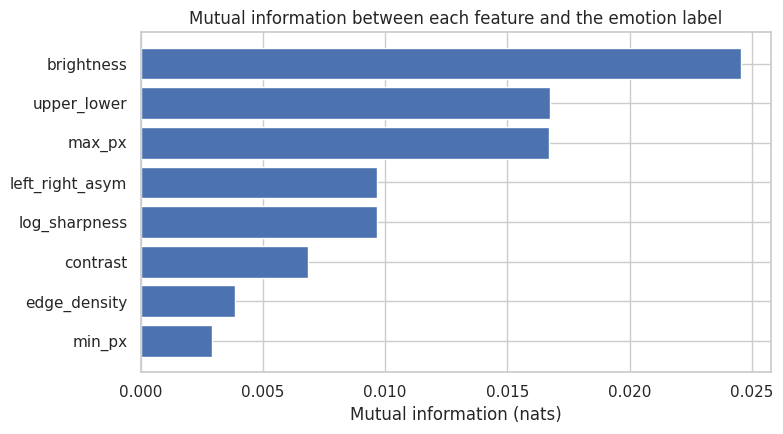

brightness         0.025
upper_lower        0.017
max_px             0.017
left_right_asym    0.010
log_sharpness      0.010
contrast           0.007
edge_density       0.004
min_px             0.003


In [ ]:
# Select your features wisely to avoid overfitting
from sklearn.feature_selection import mutual_info_classif
mi = pd.Series(mutual_info_classif(df[SELECTED_FEATURES], df['y'], random_state=RANDOM_STATE), index=SELECTED_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(mi.index, mi.values, color='#4c72b0')
ax.set(title='Mutual information between each feature and the emotion label', xlabel='Mutual information (nats)')
plt.tight_layout()
plt.show()
print(mi.sort_values(ascending=False).round(3).to_string())

##### What all feature selection methods have you used  and why?

Two complementary filters were used: (1) **correlation filtering** (drop one of any pair with |r| >= 0.75, which removes `grad_mag`, redundant with sharpness/edge strength, as chart 12 predicted) to avoid multicollinearity, and (2) **mutual information** with the label to rank what is left, because it captures non-linear relationships and works for a categorical target. Filters are cheap and model-independent, which suits a pipeline where the main model (the CNN) learns its own features.

##### Which all features you found important and why?

Mutual information is **very low for every feature (all below about 0.03 nats)**, which confirms the EDA: **brightness** (about 0.025), the **upper-lower brightness difference** and the **brightest pixel** (about 0.017 each) carry the most, still small, information, while **edge density**, the **darkest pixel** and **contrast** are lowest (below 0.01). The take-away is that no hand-crafted global feature is strongly informative, so the CNN must learn **local spatial features** (eyes, brows, mouth) from the pixels.

### 6. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

**Yes, two transformations.** (1) For the tabular baseline, **sharpness was log-transformed** (`log1p`) to remove its heavy skew (see the cell above). (2) For the neural networks, **pixels are converted to tensors, scaled to [0, 1] and standardised** (next sections). Neural networks train faster and more stably when inputs are on a similar scale and roughly zero-centred.

### 7. Data Splitting

In [ ]:
# Split your data to train and test. Choose Splitting ratio wisely.
from sklearn.model_selection import train_test_split

trainval_df = df[df['split'] == 'train']
test_df = df[df['split'] == 'validation'].reset_index(drop=True)          # the provided 'validation' folder becomes our untouched TEST set
train_df, val_df = train_test_split(trainval_df, test_size=0.15, stratify=trainval_df['y'], random_state=RANDOM_STATE)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)

sizes = pd.DataFrame({'images': [len(train_df), len(val_df), len(test_df)]}, index=['train', 'val', 'test'])
sizes['share_%'] = (sizes['images'] / sizes['images'].sum() * 100).round(1)
display(sizes)
class_share = pd.DataFrame({n: f['label'].value_counts(normalize=True) for n, f in [('train', train_df), ('val', val_df), ('test', test_df)]}).reindex(EMOTIONS)
display((class_share * 100).round(1))

,images,share_%
train,23375,68.8
val,4126,12.1
test,6474,19.1


,train,val,test
label,,,
angry,13.9,13.9,13.8
disgust,1.4,1.4,1.3
fear,14.1,14.1,14.1
happy,25.6,25.6,27.1
neutral,17.7,17.7,18.3
sad,17.6,17.6,16.7
surprise,9.7,9.7,8.8


##### What data splitting ratio have you used and why?

The result is **about 69% train (23,375), 12% validation (4,126) and 19% test (6,474)**. The provided validation folder is kept as a **final test set** that is used only once, and a **stratified 15% of the training images** becomes the validation set used for early stopping, hyperparameter tuning and model selection. Stratification keeps every class share almost identical across the three sets (see the table). Splitting was done **before** any statistic is learned from the data (pixel mean/std, class weights), so there is no information leakage; duplicates and train/test overlaps were already removed.

### 8. Data Scaling

In [ ]:
# Scaling your data
# Pixel statistics are computed on the TRAINING images only (no leakage from validation/test).
pix_sum, pix_sq, pix_n = 0.0, 0.0, 0
for p in train_df['path']:
    a = cv2.imread(p, cv2.IMREAD_GRAYSCALE).astype(np.float64) / 255.0
    pix_sum += a.sum(); pix_sq += (a ** 2).sum(); pix_n += a.size
PIXEL_MEAN = pix_sum / pix_n
PIXEL_STD = float(np.sqrt(pix_sq / pix_n - PIXEL_MEAN ** 2))
print(f'Training-set pixel mean = {PIXEL_MEAN:.4f}, std = {PIXEL_STD:.4f}  (pixels scaled to [0, 1] first)')

Training-set pixel mean = 0.5056, std = 0.2549  (pixels scaled to [0, 1] first)


##### Which method have you used to scale you data and why?

**Standardisation of pixels with the training-set mean and standard deviation** (after dividing by 255). Contrast stretching or histogram equalisation was not needed because most images already use the full 0-255 range (EDA chart 17). The pretrained ResNet18 instead receives the **ImageNet mean/std** it was trained with, and the grayscale channel is replicated to three channels. Tree-based models need no scaling.

### 9. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**No.** The cell below shows that PCA needs about 100 components to keep 90% and over 200 to keep 95% of the pixel variance, so the information is spread over many directions, and CNNs exploit the 2D structure of the image directly. Reducing to a few components would discard the fine local detail that identifies expressions. PCA was used earlier only for visualisation (chart 14).

In [ ]:
# DImensionality Reduction (If needed)  -> only used to justify NOT reducing
pca_sample = train_df.sample(4000, random_state=RANDOM_STATE)
X_pix = np.stack([cv2.imread(p, cv2.IMREAD_GRAYSCALE).ravel() for p in pca_sample['path']]).astype(np.float32) / 255.0
cum_var = np.cumsum(PCA(n_components=300, random_state=RANDOM_STATE).fit(X_pix).explained_variance_ratio_)
for target in (0.80, 0.90, 0.95):
    print(f'Components needed for {target:.0%} of the pixel variance: {int((cum_var < target).sum()) + 1}  (out of 2,304 pixels)')

Components needed for 80% of the pixel variance: 32  (out of 2,304 pixels)
Components needed for 90% of the pixel variance: 100  (out of 2,304 pixels)
Components needed for 95% of the pixel variance: 235  (out of 2,304 pixels)


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None was applied to the model inputs. PCA was used only for visualisation and to justify this decision.

### 10. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

**Yes, strongly.** In the training set happy is about 19x larger than disgust (see the cell below). A model that always predicts 'happy' would already reach about 27% accuracy, and the rare classes would almost never be predicted, which is why accuracy alone is a poor metric here.

In [ ]:
# Handling Imbalanced Dataset (If needed)
train_counts = train_df['y'].value_counts().sort_index().values
CLASS_WEIGHT_POWER = 0.5                                   # 1.0 = full inverse frequency, 0 = no weighting
class_weights_np = (len(train_df) / (len(EMOTIONS) * train_counts)) ** CLASS_WEIGHT_POWER
class_weights_np = class_weights_np / class_weights_np.mean()          # keep the average weight at 1
weights_table = pd.DataFrame({'train images': train_counts, 'loss weight': class_weights_np.round(2)}, index=EMOTIONS)
display(weights_table)
print(f'Majority-class (always "happy") accuracy on the test set: {(test_df["y"] == CLASS_TO_IDX["happy"]).mean():.1%}')

,train images,loss weight
angry,3250,0.79
disgust,320,2.51
fear,3305,0.78
happy,5985,0.58
neutral,4133,0.70
sad,4104,0.70
surprise,2278,0.94


Majority-class (always "happy") accuracy on the test set: 27.1%


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

A **class-weighted cross-entropy loss with softened inverse-frequency weights** (inverse frequency raised to the power 0.5, then normalised to mean 1) combined with **label smoothing (0.1)** and the **training augmentation** of Section 7. Full inverse-frequency weights would give disgust a weight above 10 and make training unstable on only 320 images; the square root keeps the rare classes influential without dominating the gradient. Oversampling would repeat the same few disgust images many times and invite memorisation, and SMOTE-style synthetic samples are not meaningful for faces. Evaluation uses **macro-averaged metrics and per-class recall**, so a model cannot hide behind the large classes.

## ***7. ML Model Implementation***

### Evaluation helpers and experiment log

All models are scored with the same helpers on the same validation set (used for tuning and model selection) and the same untouched test set. **Macro-averaged** metrics are the headline numbers because every emotion counts equally, whereas plain accuracy is dominated by happy, neutral and sad.

In [ ]:
# Evaluation helpers shared by all models (scikit-learn only, no PyTorch needed)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)

RESULTS = {}      # experiment log: model name -> metrics and probabilities on validation and test

def metrics_from_probs(probs, labels):
    preds = probs.argmax(1)
    pr, rc, f1m, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    return {'accuracy': accuracy_score(labels, preds), 'macro_precision': pr, 'macro_recall': rc, 'macro_f1': f1m,
            'weighted_f1': f1_score(labels, preds, average='weighted', zero_division=0)}

def register(name, val_probs, val_labels, test_probs, test_labels):
    RESULTS[name] = {'val': metrics_from_probs(val_probs, val_labels), 'test': metrics_from_probs(test_probs, test_labels),
                     'val_probs': val_probs, 'test_probs': test_probs}

def plot_evaluation(title, probs, labels):
    # Metric score chart + per-class precision/recall/F1 + normalised confusion matrix.
    preds = probs.argmax(1)
    m = metrics_from_probs(probs, labels)
    pr, rc, f1c, _ = precision_recall_fscore_support(labels, preds, labels=range(len(EMOTIONS)), zero_division=0)
    cm = confusion_matrix(labels, preds, labels=range(len(EMOTIONS)), normalize='true')
    fig, axes = plt.subplots(1, 3, figsize=(21, 5.2))
    names = ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']
    bars = axes[0].bar([n.replace('_', '\n') for n in names], [m[n] for n in names], color=['#4c72b0', '#55a868', '#c44e52', '#8172b3'])
    for b in bars:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f'{b.get_height():.3f}', ha='center')
    axes[0].set(title=f'{title}: evaluation metric scores', ylim=(0, 1.05))
    x = np.arange(len(EMOTIONS)); w = 0.27
    axes[1].bar(x - w, pr, w, label='precision'); axes[1].bar(x, rc, w, label='recall'); axes[1].bar(x + w, f1c, w, label='F1')
    axes[1].set_xticks(x); axes[1].set_xticklabels(EMOTIONS, rotation=30); axes[1].set(title='Per-class scores', ylim=(0, 1.05)); axes[1].legend()
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=EMOTIONS, yticklabels=EMOTIONS, vmin=0, vmax=1, ax=axes[2], cbar=False)
    axes[2].set(title='Normalised confusion matrix (rows = true class)', xlabel='Predicted', ylabel='True')
    plt.tight_layout()
    plt.show()
    print(classification_report(labels, preds, target_names=EMOTIONS, digits=3, zero_division=0))
    return m

### ML Model - 1: Random Forest on hand-crafted image statistics (classical baseline)

In [ ]:
# ML Model - 1 Implementation
X_train, y_train = train_df[SELECTED_FEATURES], train_df['y']
X_val, y_val = val_df[SELECTED_FEATURES], val_df['y']
X_test, y_test = test_df[SELECTED_FEATURES], test_df['y']

# Fit the Algorithm
rf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1)
rf.fit(X_train, y_train)

# Predict on the model
register('Random Forest (default)', rf.predict_proba(X_val), y_val.values, rf.predict_proba(X_test), y_test.values)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

A **Random Forest** averages many decision trees trained on random subsets of rows and features. It is a strong, assumption-free tabular model, so it is the fair classical baseline: if hand-crafted statistics could separate emotions, this model would show it. It uses the selected features (brightness, contrast, log-sharpness, edge density, asymmetry, upper-lower difference, darkest and brightest pixel) and `class_weight='balanced'` for the imbalance. Chart below: test-set scores.

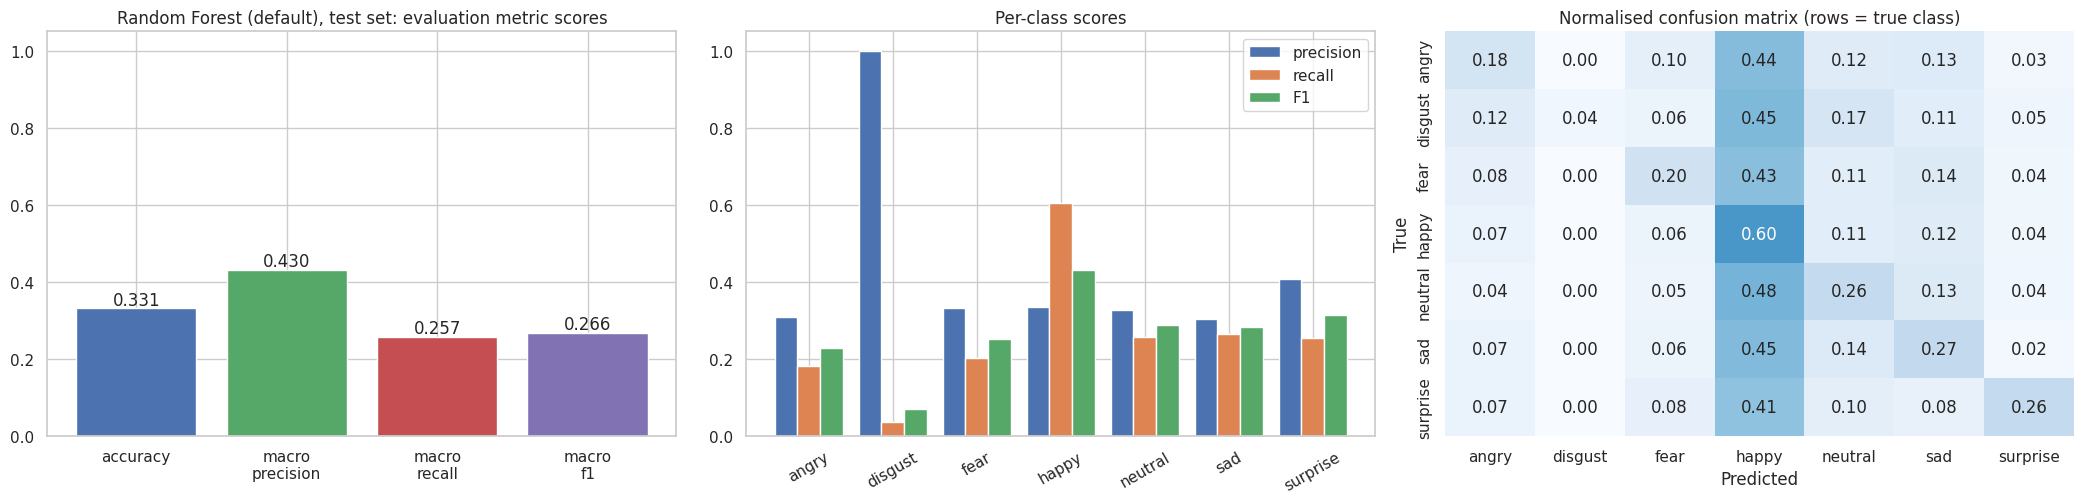

              precision    recall  f1-score   support

       angry      0.307     0.181     0.228       893
     disgust      1.000     0.037     0.071        82
        fear      0.333     0.201     0.251       914
       happy      0.335     0.603     0.431      1752
     neutral      0.327     0.257     0.288      1182
         sad      0.302     0.265     0.282      1083
    surprise      0.407     0.255     0.314       568

    accuracy                          0.331      6474
   macro avg      0.430     0.257     0.266      6474
weighted avg      0.339     0.331     0.312      6474



In [ ]:
# Visualizing evaluation Metric Score chart
_ = plot_evaluation('Random Forest (default), test set', RESULTS['Random Forest (default)']['test_probs'], y_test.values)

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters      : {'n_estimators': 200, 'min_samples_leaf': 1, 'max_depth': None}
Cross-validated macro-F1 (3-fold): 0.249


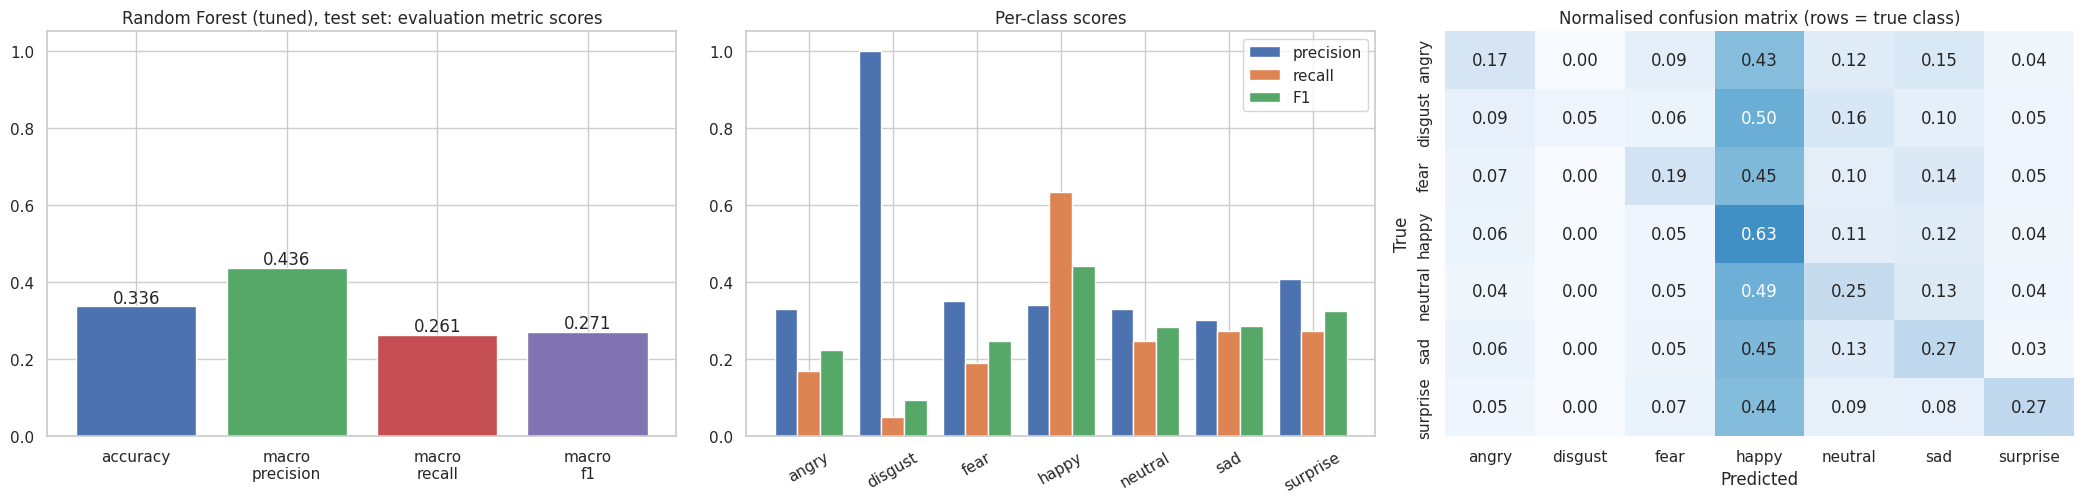

              precision    recall  f1-score   support

       angry      0.330     0.169     0.224       893
     disgust      1.000     0.049     0.093        82
        fear      0.349     0.189     0.246       914
       happy      0.339     0.632     0.441      1752
     neutral      0.329     0.247     0.282      1182
         sad      0.300     0.271     0.285      1083
    surprise      0.406     0.271     0.325       568

    accuracy                          0.336      6474
   macro avg      0.436     0.261     0.271      6474
weighted avg      0.345     0.336     0.314      6474



In [ ]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (RandomizedSearchCV with 3-fold stratified cross-validation)
param_dist = {'n_estimators': [100, 200], 'max_depth': [8, 12, None], 'min_samples_leaf': [1, 5, 10]}
search = RandomizedSearchCV(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1),
                            param_dist, n_iter=6, cv=3, scoring='f1_macro', random_state=RANDOM_STATE, n_jobs=1)

# Fit the Algorithm
search.fit(X_train, y_train)
rf_best = search.best_estimator_
print('Best parameters      :', search.best_params_)
print(f'Cross-validated macro-F1 (3-fold): {search.best_score_:.3f}')

# Predict on the model
register('Random Forest (tuned)', rf_best.predict_proba(X_val), y_val.values, rf_best.predict_proba(X_test), y_test.values)
_ = plot_evaluation('Random Forest (tuned), test set', RESULTS['Random Forest (tuned)']['test_probs'], y_test.values)

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV with 3-fold stratified cross-validation, scored on macro-F1.** Random search samples 6 of the 18 possible combinations per fold instead of fitting all of them, and macro-F1 stops the search from rewarding a model that ignores rare classes. Cross-validation (rather than one split) makes the choice less dependent on a lucky split.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Tuning changes the scores only slightly, and the tuned model stays **close to chance level**: test accuracy is about **34%**, only a few points above the **27%** obtained by always predicting 'happy', and macro-F1 is about **0.27**. Disgust is almost never recognised (recall about 5%, F1 about 0.09) while happy is the best class (F1 about 0.44, recall 63%). This is the key result of the baseline: **global image statistics cannot recognise emotions**, exactly as the EDA predicted, so the deep models that follow are needed. (Exact figures may vary slightly between library versions.)

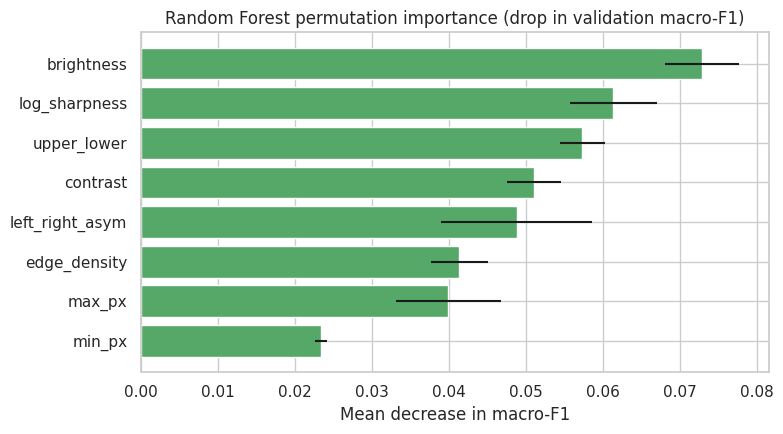

brightness         0.0729
log_sharpness      0.0614
upper_lower        0.0573
contrast           0.0511
left_right_asym    0.0488
edge_density       0.0414
max_px             0.0399
min_px             0.0234


In [ ]:
# Model explainability for Model 1: permutation importance on the validation set
perm = permutation_importance(rf_best, X_val, y_val, scoring='f1_macro', n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=SELECTED_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp.values, xerr=pd.Series(perm.importances_std, index=SELECTED_FEATURES)[imp.index].values, color='#55a868')
ax.set(title='Random Forest permutation importance (drop in validation macro-F1)', xlabel='Mean decrease in macro-F1')
plt.tight_layout()
plt.show()
print(imp.sort_values(ascending=False).round(4).to_string())

**Feature importance (Model 1):** permuting a single feature lowers validation macro-F1 by roughly 0.02 to 0.07, with **brightness (about 0.07), log-sharpness and the upper-lower difference (about 0.06)** at the top and the darkest pixel at the bottom. The importance is spread fairly evenly across features and the model's absolute score stays low, so no single hand-crafted feature is decisive.

### PyTorch setup (Models 2 and 3, GPU recommended)

From here on the notebook uses **PyTorch**. The setup below builds the data pipeline (cached images, augmentation, loaders), the shared training loop (AdamW, one-cycle learning-rate schedule, mixed precision, gradient clipping, early stopping on validation macro-F1) and the prediction helpers.

In [ ]:
# PyTorch imports and device setup
import time, copy, random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image

def seed_everything(seed=RANDOM_STATE):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'                          # mixed precision only makes sense on GPU
NUM_WORKERS = min(4, os.cpu_count() or 2)
CLASS_WEIGHTS = torch.tensor(class_weights_np, dtype=torch.float32)
print(f'torch {torch.__version__} | device: {DEVICE} | mixed precision: {USE_AMP} | workers: {NUM_WORKERS}')
if DEVICE.type == 'cpu':
    print('WARNING: no GPU found - training will be very slow. In Colab choose Runtime > Change runtime type > GPU.')

torch 2.11.0+cu130 | device: cuda | mixed precision: True | workers: 2


In [ ]:
# Data pipeline: cache all (small) images in memory once, then wrap them in Datasets with augmentation
def load_images(frame):
    return [Image.fromarray(cv2.imread(p, cv2.IMREAD_GRAYSCALE)) for p in frame['path']]

IMAGES = {'train': load_images(train_df), 'val': load_images(val_df), 'test': load_images(test_df)}
LABELS = {'train': train_df['y'].to_numpy(), 'val': val_df['y'].to_numpy(), 'test': test_df['y'].to_numpy()}
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

class FERDataset(Dataset):
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.transform(self.images[i]), int(self.labels[i])

def make_transforms(three_channel, img_size, mean=None, std=None):
    # Label-preserving augmentation for training (justified by the EDA); deterministic transform for evaluation.
    if mean is None:
        mean, std = (IMAGENET_MEAN, IMAGENET_STD) if three_channel else ((PIXEL_MEAN,), (PIXEL_STD,))
    pre = [transforms.Grayscale(num_output_channels=3)] if three_channel else []
    resize = [transforms.Resize((img_size, img_size))] if img_size != 48 else []
    norm = [transforms.ToTensor(), transforms.Normalize(mean, std)]
    train_tf = transforms.Compose(pre + resize + [
        transforms.RandomHorizontalFlip(),                                       # faces are naturally asymmetric (chart 7)
        transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1)),   # pose / alignment variation
        transforms.ColorJitter(brightness=0.3, contrast=0.3),                    # lighting robustness (hypotheses 1-2)
    ] + norm)
    eval_tf = transforms.Compose(pre + resize + norm)
    return train_tf, eval_tf

def make_loaders(three_channel, img_size, batch_size=128):
    train_tf, eval_tf = make_transforms(three_channel, img_size)
    tfs = {'train': train_tf, 'val': eval_tf, 'test': eval_tf}
    loaders = {}
    for k in ['train', 'val', 'test']:
        loaders[k] = DataLoader(FERDataset(IMAGES[k], LABELS[k], tfs[k]), batch_size=batch_size, shuffle=(k == 'train'),
                                drop_last=(k == 'train'), num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'))
    return loaders

print({k: len(v) for k, v in IMAGES.items()})

{'train': 23375, 'val': 4126, 'test': 6474}


In [ ]:
# Shared training and evaluation utilities
def make_scaler():
    if hasattr(torch.amp, 'GradScaler'):
        return torch.amp.GradScaler('cuda', enabled=USE_AMP)
    return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, n, preds_all, labels_all = 0.0, 0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(train):
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                logits = model(xb)
                loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)          # stabilise training
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
        total_loss += loss.item() * xb.size(0); n += xb.size(0)
        preds_all.append(logits.argmax(1).detach().cpu()); labels_all.append(yb.cpu())
    preds, labels = torch.cat(preds_all).numpy(), torch.cat(labels_all).numpy()
    return {'loss': total_loss / n, 'acc': accuracy_score(labels, preds), 'f1': f1_score(labels, preds, average='macro')}

def train_model(model, loaders, cfg, name, verbose=True):
    # AdamW + one-cycle LR + class-weighted label-smoothed loss + early stopping on validation macro-F1.
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE), label_smoothing=cfg.get('label_smoothing', 0.1))
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=cfg['lr'], total_steps=cfg['epochs'] * len(loaders['train']), pct_start=0.2)
    scaler = make_scaler()
    best_f1, best_state, bad_epochs, history = -1.0, None, 0, []
    for epoch in range(1, cfg['epochs'] + 1):
        t0 = time.time()
        tr = run_epoch(model, loaders['train'], criterion, optimizer, scheduler, scaler)
        va = run_epoch(model, loaders['val'], criterion)
        history.append({'epoch': epoch, 'train_loss': tr['loss'], 'val_loss': va['loss'], 'train_f1': tr['f1'], 'val_f1': va['f1'], 'val_acc': va['acc']})
        if va['f1'] > best_f1 + 1e-4:
            best_f1, best_state, bad_epochs = va['f1'], copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
        if verbose:
            print(f"[{name}] epoch {epoch:02d}/{cfg['epochs']}  train loss {tr['loss']:.3f}  val loss {va['loss']:.3f}  "
                  f"val acc {va['acc']:.3f}  val macro-F1 {va['f1']:.3f}  ({time.time() - t0:.0f}s)")
        if bad_epochs >= cfg['patience']:
            if verbose: print(f'[{name}] early stopping: no improvement for {cfg["patience"]} epochs')
            break
    model.load_state_dict(best_state)                       # restore the best epoch
    return model, pd.DataFrame(history)

@torch.no_grad()
def get_probs(model, loader, tta=False):
    # Softmax probabilities; with tta=True the prediction is averaged with that of the horizontally flipped image.
    model.eval()
    probs, labels = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            p = model(xb).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(xb, dims=[3])).float().softmax(1)) / 2
        probs.append(p.cpu()); labels.append(yb)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy()

def evaluate_and_register(name, model, loaders, tta=False):
    val_p, val_y = get_probs(model, loaders['val'], tta)
    test_p, test_y = get_probs(model, loaders['test'], tta)
    register(name, val_p, val_y, test_p, test_y)
    return test_p, test_y

def plot_history(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist['epoch'], hist['train_loss'], label='train'); axes[0].plot(hist['epoch'], hist['val_loss'], label='validation')
    axes[0].set(title=f'{title}: loss', xlabel='epoch'); axes[0].legend()
    axes[1].plot(hist['epoch'], hist['train_f1'], label='train'); axes[1].plot(hist['epoch'], hist['val_f1'], label='validation')
    axes[1].set(title=f'{title}: macro-F1', xlabel='epoch'); axes[1].legend()
    plt.tight_layout(); plt.show()

### ML Model - 2: Custom CNN trained from scratch

In [ ]:
# ML Model - 2 definition: four double-convolution blocks -> global average pooling -> small classifier
class ConvBlock(nn.Module):
    def __init__(self, c_in, c_out, p_drop=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout2d(p_drop))
    def forward(self, x):
        return self.net(x)

class EmotionCNN(nn.Module):
    def __init__(self, n_classes=7, widths=(32, 64, 128, 256), dropout=0.4):
        super().__init__()
        chans = (1,) + tuple(widths)
        self.features = nn.Sequential(*[ConvBlock(chans[i], chans[i + 1]) for i in range(len(widths))])
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(widths[-1], 128), nn.ReLU(),
                                        nn.Dropout(dropout), nn.Linear(128, n_classes))
    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

print(f'Parameters: {sum(p.numel() for p in EmotionCNN().parameters()):,}')
print(EmotionCNN())

Parameters: 1,206,439
EmotionCNN(
  (features): Sequential(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU()
        (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.1, inplace=False)
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
 

[Custom CNN] epoch 01/30  train loss 2.007  val loss 1.980  val acc 0.259  val macro-F1 0.108  (16s)
[Custom CNN] epoch 02/30  train loss 1.986  val loss 1.970  val acc 0.273  val macro-F1 0.151  (12s)
[Custom CNN] epoch 03/30  train loss 1.950  val loss 1.878  val acc 0.327  val macro-F1 0.192  (12s)
[Custom CNN] epoch 04/30  train loss 1.833  val loss 1.692  val acc 0.454  val macro-F1 0.330  (12s)
[Custom CNN] epoch 05/30  train loss 1.730  val loss 1.743  val acc 0.430  val macro-F1 0.289  (13s)
[Custom CNN] epoch 06/30  train loss 1.678  val loss 1.572  val acc 0.519  val macro-F1 0.385  (12s)
[Custom CNN] epoch 07/30  train loss 1.639  val loss 1.534  val acc 0.546  val macro-F1 0.419  (12s)
[Custom CNN] epoch 08/30  train loss 1.611  val loss 1.531  val acc 0.530  val macro-F1 0.396  (13s)
[Custom CNN] epoch 09/30  train loss 1.590  val loss 1.483  val acc 0.562  val macro-F1 0.431  (13s)
[Custom CNN] epoch 10/30  train loss 1.569  val loss 1.471  val acc 0.572  val macro-F1 0.4

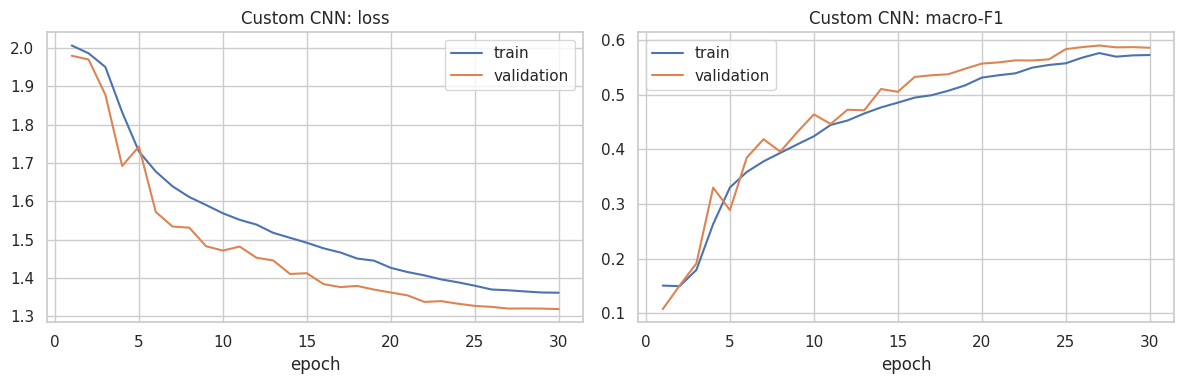

In [ ]:
# ML Model - 2 Implementation
loaders_cnn = make_loaders(three_channel=False, img_size=48)

# Fit the Algorithm
seed_everything()
cnn_cfg = dict(lr=2e-3, weight_decay=1e-4, epochs=30, patience=8, label_smoothing=0.1)
cnn, cnn_hist = train_model(EmotionCNN(dropout=0.4), loaders_cnn, cnn_cfg, 'Custom CNN')
plot_history(cnn_hist, 'Custom CNN')

# Predict on the model
test_p, test_y = evaluate_and_register('Custom CNN', cnn, loaders_cnn)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**Architecture and justification.** Four blocks of *Conv-BatchNorm-ReLU x2 + MaxPool + Dropout2d* (32, 64, 128, 256 filters) halve the 48x48 map to 3x3 while doubling the channels. **Double 3x3 convolutions** give a large receptive field with few parameters (about 1.2 million); **batch normalisation** stabilises and speeds up training; **ReLU** is cheap and avoids vanishing gradients; **spatial dropout and a dropout-regularised head** fight overfitting on only 23k images; **global average pooling** removes the large flatten layer and makes the model robust to small shifts, which also keeps it small and fast for real-time use. Training uses **AdamW** (decoupled weight decay), a **one-cycle learning-rate schedule** (fast convergence), **mixed precision**, **gradient clipping** and **early stopping on validation macro-F1**.

**Results:** the CNN trained from scratch reaches a test accuracy of 63.4% and a macro-F1 of 0.565 with default settings, and 65.1% and 0.599 after tuning. Per-class scores of the tuned model show the same pattern as the other models: happy is the best class (F1 0.87), followed by surprise (0.73) and neutral (0.64), while fear is clearly the weakest (F1 0.40). Fear has a decent precision (0.58) but a very low recall of 0.31, meaning that the model rarely predicts fear and misses about two thirds of real fear images, which are probably absorbed by the neighbouring classes (check the confusion matrix). Disgust reaches an F1 of 0.47, but with only 82 test images this estimate is noisy. The training and validation losses stay close together (about 1.31 and 1.30 at the end), so the model is not overfitting; validation macro-F1 was still creeping up in the last epochs, so longer training could help a little.

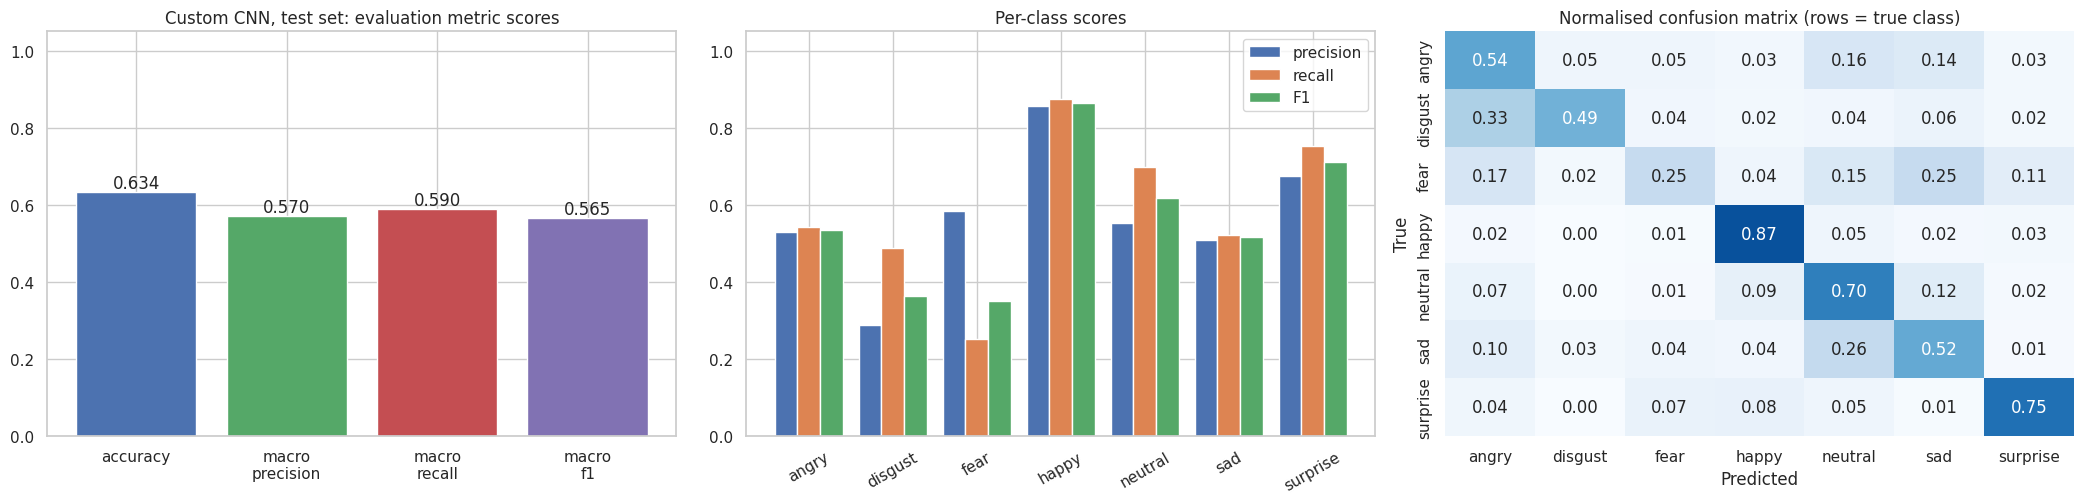

              precision    recall  f1-score   support

       angry      0.530     0.541     0.535       893
     disgust      0.288     0.488     0.362        82
        fear      0.583     0.251     0.350       914
       happy      0.856     0.874     0.865      1752
     neutral      0.552     0.699     0.617      1182
         sad      0.509     0.522     0.515      1083
    surprise      0.674     0.754     0.712       568

    accuracy                          0.634      6474
   macro avg      0.570     0.590     0.565      6474
weighted avg      0.636     0.634     0.623      6474



In [ ]:
# Visualizing evaluation Metric Score chart
_ = plot_evaluation('Custom CNN, test set', test_p, test_y)

#### 2. Cross- Validation & Hyperparameter Tuning

trial 1: {'lr': 0.001, 'dropout': 0.3, 'weight_decay': 0.0001} -> best val macro-F1 0.418
trial 2: {'lr': 0.003, 'dropout': 0.3, 'weight_decay': 0.0001} -> best val macro-F1 0.392
trial 3: {'lr': 0.001, 'dropout': 0.5, 'weight_decay': 0.0005} -> best val macro-F1 0.378
trial 4: {'lr': 0.003, 'dropout': 0.5, 'weight_decay': 0.0005} -> best val macro-F1 0.327


,lr,dropout,weight_decay,best_val_macro_f1
0,0.001,0.3,0.0001,0.417970
1,0.003,0.3,0.0001,0.392364
2,0.001,0.5,0.0005,0.377948
3,0.003,0.5,0.0005,0.326965


[Custom CNN (tuned)] epoch 01/40  train loss 2.006  val loss 1.972  val acc 0.257  val macro-F1 0.122  (12s)
[Custom CNN (tuned)] epoch 02/40  train loss 1.987  val loss 1.962  val acc 0.270  val macro-F1 0.145  (12s)
[Custom CNN (tuned)] epoch 03/40  train loss 1.973  val loss 1.922  val acc 0.317  val macro-F1 0.185  (12s)
[Custom CNN (tuned)] epoch 04/40  train loss 1.870  val loss 1.738  val acc 0.433  val macro-F1 0.324  (12s)
[Custom CNN (tuned)] epoch 05/40  train loss 1.744  val loss 1.760  val acc 0.417  val macro-F1 0.293  (12s)
[Custom CNN (tuned)] epoch 06/40  train loss 1.687  val loss 1.601  val acc 0.496  val macro-F1 0.347  (12s)
[Custom CNN (tuned)] epoch 07/40  train loss 1.641  val loss 1.576  val acc 0.516  val macro-F1 0.414  (12s)
[Custom CNN (tuned)] epoch 08/40  train loss 1.611  val loss 1.552  val acc 0.525  val macro-F1 0.403  (12s)
[Custom CNN (tuned)] epoch 09/40  train loss 1.581  val loss 1.502  val acc 0.555  val macro-F1 0.452  (12s)
[Custom CNN (tuned)

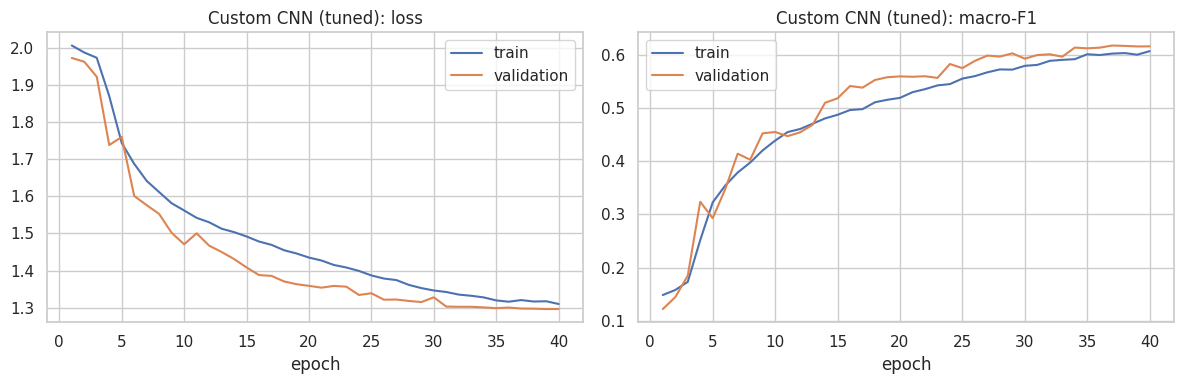

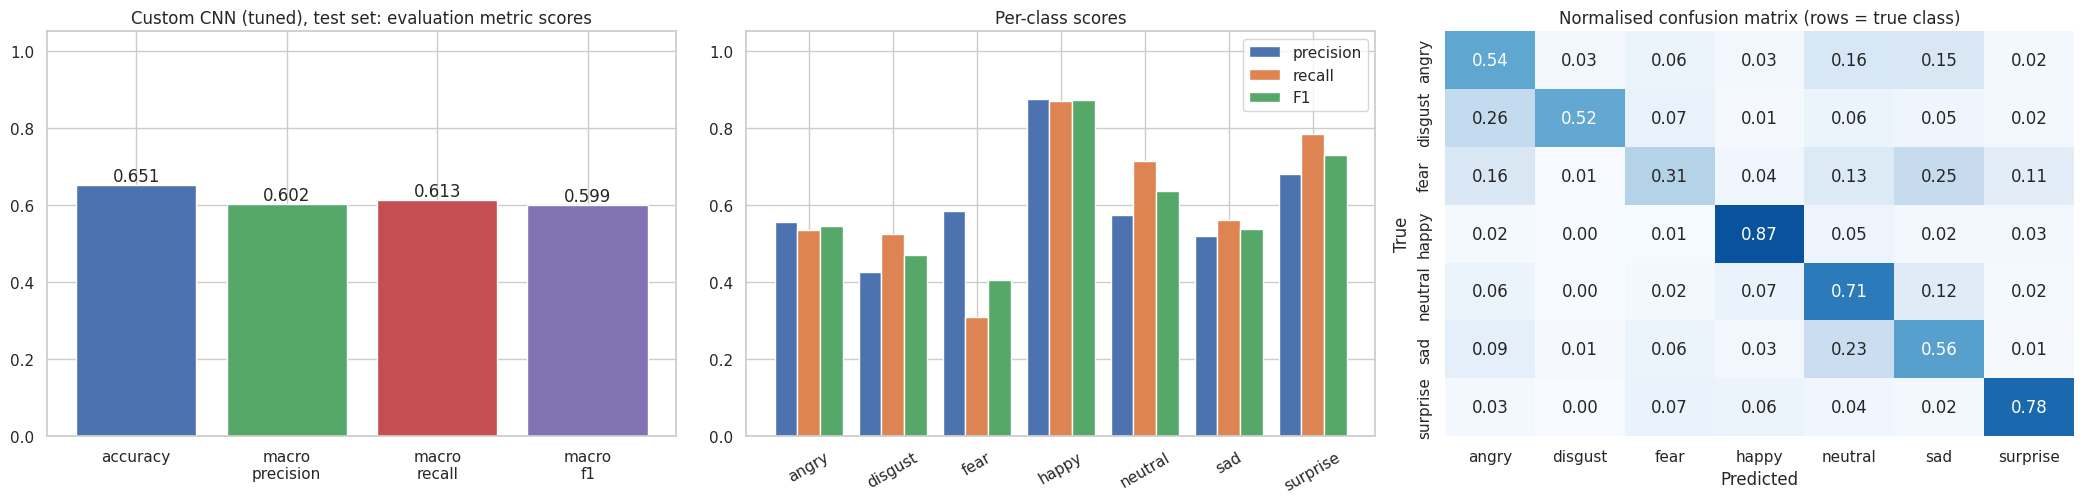

              precision    recall  f1-score   support

       angry      0.555     0.535     0.545       893
     disgust      0.426     0.524     0.470        82
        fear      0.583     0.309     0.403       914
       happy      0.875     0.868     0.872      1752
     neutral      0.574     0.712     0.636      1182
         sad      0.518     0.560     0.538      1083
    surprise      0.680     0.783     0.728       568

    accuracy                          0.651      6474
   macro avg      0.602     0.613     0.599      6474
weighted avg      0.652     0.651     0.644      6474



In [ ]:
# ML Model - 2 Implementation with hyperparameter optimization (small random search on the VALIDATION set, short runs)
search_space = [dict(lr=1e-3, dropout=0.3, weight_decay=1e-4), dict(lr=3e-3, dropout=0.3, weight_decay=1e-4),
                dict(lr=1e-3, dropout=0.5, weight_decay=5e-4), dict(lr=3e-3, dropout=0.5, weight_decay=5e-4)]
rows = []
for i, hp in enumerate(search_space, 1):
    seed_everything()
    trial_cfg = dict(lr=hp['lr'], weight_decay=hp['weight_decay'], epochs=8, patience=8, label_smoothing=0.1)
    trial_model, trial_hist = train_model(EmotionCNN(dropout=hp['dropout']), loaders_cnn, trial_cfg, f'CNN trial {i}', verbose=False)
    rows.append({**hp, 'best_val_macro_f1': trial_hist['val_f1'].max()})
    print(f'trial {i}: {hp} -> best val macro-F1 {trial_hist["val_f1"].max():.3f}')
    del trial_model
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
search_df = pd.DataFrame(rows).sort_values('best_val_macro_f1', ascending=False)
display(search_df)
best_hp = search_df.iloc[0].to_dict()

# Fit the Algorithm: retrain longer with the best hyperparameters
seed_everything()
tuned_cfg = dict(lr=best_hp['lr'], weight_decay=best_hp['weight_decay'], epochs=40, patience=10, label_smoothing=0.1)
cnn_tuned, cnn_tuned_hist = train_model(EmotionCNN(dropout=best_hp['dropout']), loaders_cnn, tuned_cfg, 'Custom CNN (tuned)')
plot_history(cnn_tuned_hist, 'Custom CNN (tuned)')

# Predict on the model
test_p, test_y = evaluate_and_register('Custom CNN (tuned)', cnn_tuned, loaders_cnn)
_ = plot_evaluation('Custom CNN (tuned), test set', test_p, test_y)

##### Which hyperparameter optimization technique have you used and why?

A **small random/grid search over learning rate, dropout and weight decay** (4 short trials, scored on validation macro-F1), followed by a longer retraining of the best setting. These three hyperparameters have the largest effect on a from-scratch CNN, and short runs make the search affordable on a single GPU. A heavier Bayesian search (e.g. Optuna) is a natural extension. Because each trial uses a held-out validation set, the test set stays untouched. *Cross-validation* is applied to Model 1; for the deep models a fixed stratified validation split is used because k-fold training of a CNN is k times more expensive.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a clear improvement. After the hyperparameter search and longer retraining, the Custom CNN improved from a validation macro-F1 of 0.590 to 0.617, and on the test set from 0.565 to 0.599 macro-F1 and from 63.4% to 65.1% accuracy. Macro-F1 rose about twice as much as accuracy, which suggests that part of the gain came from the less frequent classes. Flip test-time augmentation added a further small gain (test accuracy 65.6%, macro-F1 0.602).

The search selected a learning rate of 1e-3, dropout of 0.3 and weight decay of 1e-4 (validation macro-F1 0.418 in the 8-epoch trials). The trials with higher regularisation or a higher learning rate scored lower (0.327 to 0.392). Note that these were short runs, which favour settings that converge quickly, and that the retraining also ran for more epochs (40 instead of 30), so part of the gain comes from longer training rather than from the hyperparameters alone.

### ML Model - 3: Transfer learning with a pretrained ResNet18

In [ ]:
# ML Model - 3 definition: ImageNet-pretrained ResNet18 with a new classification head
def build_resnet18(n_classes=7, dropout=0.3, pretrained=True):
    try:
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    except Exception as e:                                    # e.g. no internet to download the weights
        print('Could not load pretrained weights:', e, '-> falling back to random initialisation')
        m = models.resnet18(weights=None)
    m.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.fc.in_features, n_classes))
    return m

def set_backbone_trainable(model, trainable):
    for name_, p in model.named_parameters():
        if not name_.startswith('fc'):
            p.requires_grad = trainable

print(f'Parameters: {sum(p.numel() for p in build_resnet18(pretrained=False).parameters()):,}')

Parameters: 11,180,103


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


[ResNet18 head] epoch 01/5  train loss 2.153  val loss 1.934  val acc 0.331  val macro-F1 0.248  (28s)
[ResNet18 head] epoch 02/5  train loss 1.951  val loss 1.891  val acc 0.347  val macro-F1 0.261  (26s)
[ResNet18 head] epoch 03/5  train loss 1.900  val loss 1.871  val acc 0.358  val macro-F1 0.253  (27s)
[ResNet18 head] epoch 04/5  train loss 1.885  val loss 1.859  val acc 0.363  val macro-F1 0.271  (27s)
[ResNet18 head] epoch 05/5  train loss 1.877  val loss 1.852  val acc 0.373  val macro-F1 0.282  (26s)
[ResNet18 fine-tune] epoch 01/20  train loss 1.798  val loss 1.670  val acc 0.464  val macro-F1 0.376  (28s)
[ResNet18 fine-tune] epoch 02/20  train loss 1.615  val loss 1.498  val acc 0.555  val macro-F1 0.474  (28s)
[ResNet18 fine-tune] epoch 03/20  train loss 1.502  val loss 1.483  val acc 0.576  val macro-F1 0.500  (28s)
[ResNet18 fine-tune] epoch 04/20  train loss 1.433  val loss 1.442  val acc 0.598  val macro-F1 0.511  (28s)
[ResNet18 fine-tune] epoch 05/20  train loss 1.38

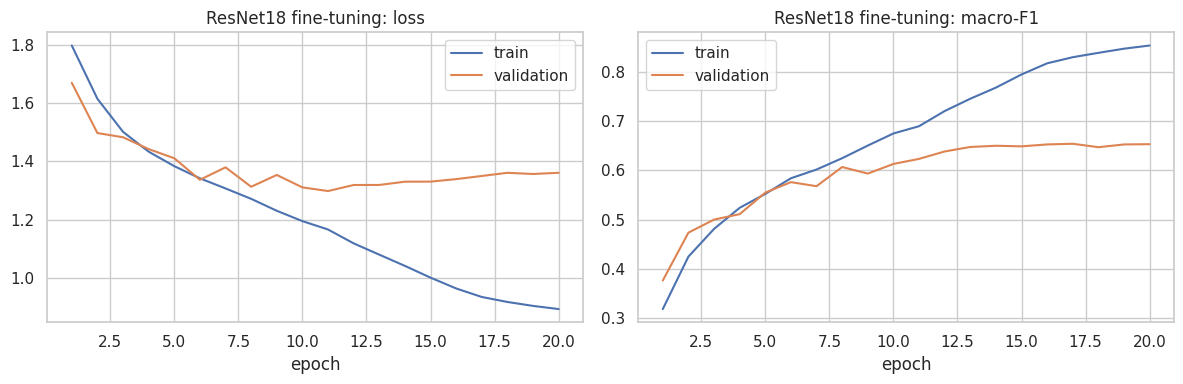

In [ ]:
# ML Model - 3 Implementation  (phase 1: train only the new head on frozen ImageNet features)
loaders_tl = make_loaders(three_channel=True, img_size=96)          # grayscale -> 3 channels, upscaled to 96x96, ImageNet normalisation

seed_everything()
resnet = build_resnet18(dropout=0.3)
set_backbone_trainable(resnet, False)
head_cfg = dict(lr=1e-3, weight_decay=1e-4, epochs=5, patience=5, label_smoothing=0.1)
resnet, head_hist = train_model(resnet, loaders_tl, head_cfg, 'ResNet18 head')
warm_state = copy.deepcopy(resnet.state_dict())                    # reused as the starting point for fine-tuning trials

# Fit the Algorithm (phase 2: unfreeze everything and fine-tune with a smaller learning rate)
set_backbone_trainable(resnet, True)
ft_cfg = dict(lr=3e-4, weight_decay=1e-4, epochs=20, patience=6, label_smoothing=0.1)
resnet, resnet_hist = train_model(resnet, loaders_tl, ft_cfg, 'ResNet18 fine-tune')
plot_history(resnet_hist, 'ResNet18 fine-tuning')

# Predict on the model
test_p, test_y = evaluate_and_register('ResNet18', resnet, loaders_tl)

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

**ResNet18** is a residual network pretrained on ImageNet. Its early layers already detect edges, textures and simple shapes that are useful for faces, and its **skip connections** make a deep network easy to optimise. We replace the classifier by *Dropout + Linear(512, 7)*, convert grayscale to three channels, upscale to 96x96 so the deep stride-32 backbone keeps a usable feature map, and train in **two phases**: (1) only the new head on frozen features, so random head weights cannot destroy the pretrained filters, then (2) the **whole network with a small learning rate** (3e-4) so it adapts to faces. This usually beats training from scratch on a modest dataset and converges in fewer epochs.

**Results:** the fine-tuned ResNet18 reaches a test accuracy of 67.1% and a macro-F1 of 0.633 (the tuned version: 67.0% and 0.635). Per-class scores of the tuned model show a clear pattern: happy is by far the best class (F1 0.88), followed by surprise (0.74) and neutral (0.65), while fear is the weakest class (F1 0.46, recall 0.42). Disgust has a precision of 0.66 but a recall of only 0.50, and with just 82 test images its score is noisy. The training curves show mild overfitting: the training loss keeps falling to about 0.96 while the validation loss levels off around 1.3 after epoch 17, so early stopping on validation macro-F1 (which restored the best epoch, epoch 20, with validation macro-F1 0.663) was useful.

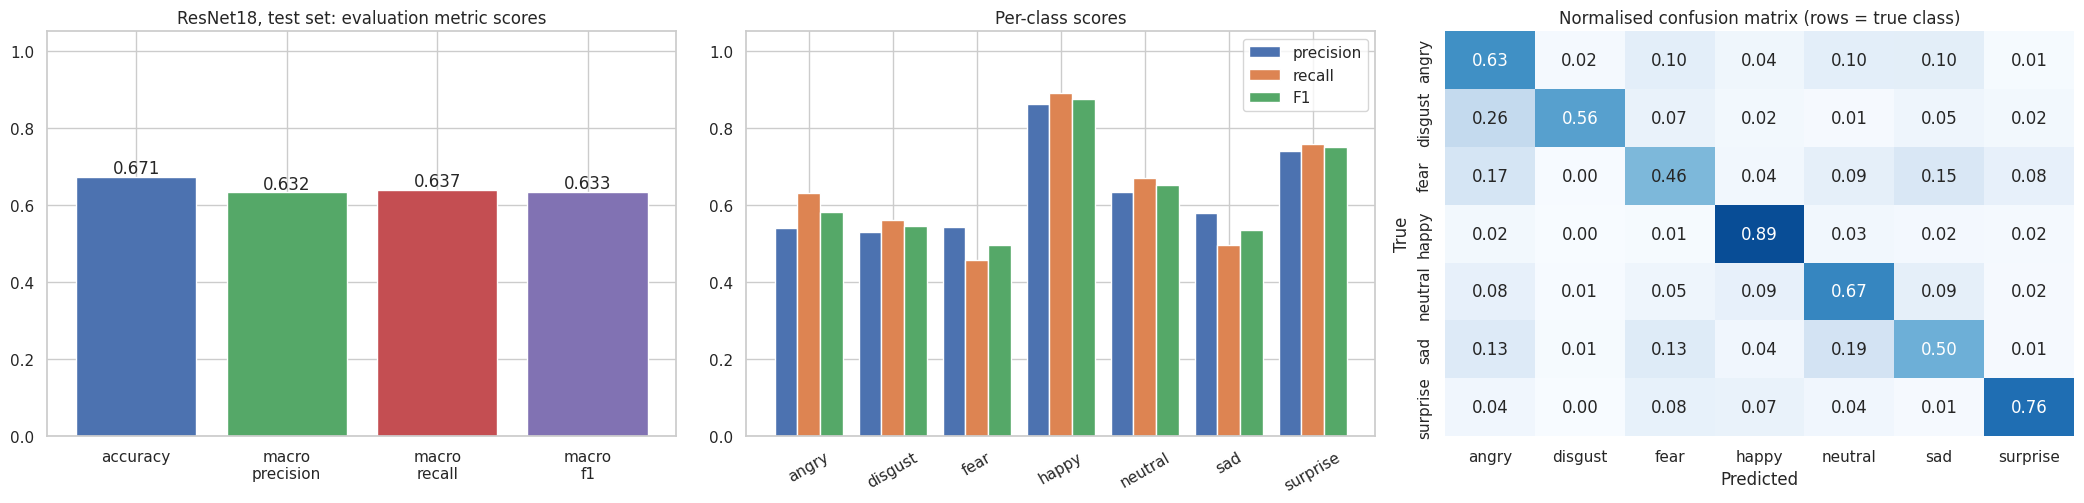

              precision    recall  f1-score   support

       angry      0.539     0.630     0.581       893
     disgust      0.529     0.561     0.544        82
        fear      0.542     0.456     0.495       914
       happy      0.861     0.890     0.876      1752
     neutral      0.632     0.669     0.650      1182
         sad      0.579     0.496     0.534      1083
    surprise      0.741     0.759     0.750       568

    accuracy                          0.671      6474
   macro avg      0.632     0.637     0.633      6474
weighted avg      0.668     0.671     0.668      6474



In [ ]:
# Visualizing evaluation Metric Score chart
_ = plot_evaluation('ResNet18, test set', test_p, test_y)

#### 2. Cross- Validation & Hyperparameter Tuning

lr=0.0001: best val macro-F1 0.584
lr=0.0003: best val macro-F1 0.610
lr=0.001: best val macro-F1 0.617


,fine_tune_lr,best_val_macro_f1
2,0.0010,0.616527
1,0.0003,0.609937
0,0.0001,0.583665


[ResNet18 (tuned)] epoch 01/25  train loss 1.724  val loss 1.561  val acc 0.529  val macro-F1 0.437  (28s)
[ResNet18 (tuned)] epoch 02/25  train loss 1.542  val loss 1.496  val acc 0.560  val macro-F1 0.504  (28s)
[ResNet18 (tuned)] epoch 03/25  train loss 1.490  val loss 1.457  val acc 0.581  val macro-F1 0.513  (28s)
[ResNet18 (tuned)] epoch 04/25  train loss 1.478  val loss 1.491  val acc 0.541  val macro-F1 0.471  (28s)
[ResNet18 (tuned)] epoch 05/25  train loss 1.454  val loss 1.712  val acc 0.470  val macro-F1 0.384  (28s)
[ResNet18 (tuned)] epoch 06/25  train loss 1.426  val loss 1.406  val acc 0.609  val macro-F1 0.550  (28s)
[ResNet18 (tuned)] epoch 07/25  train loss 1.397  val loss 1.420  val acc 0.601  val macro-F1 0.526  (28s)
[ResNet18 (tuned)] epoch 08/25  train loss 1.370  val loss 1.383  val acc 0.625  val macro-F1 0.572  (28s)
[ResNet18 (tuned)] epoch 09/25  train loss 1.346  val loss 1.429  val acc 0.597  val macro-F1 0.535  (28s)
[ResNet18 (tuned)] epoch 10/25  train

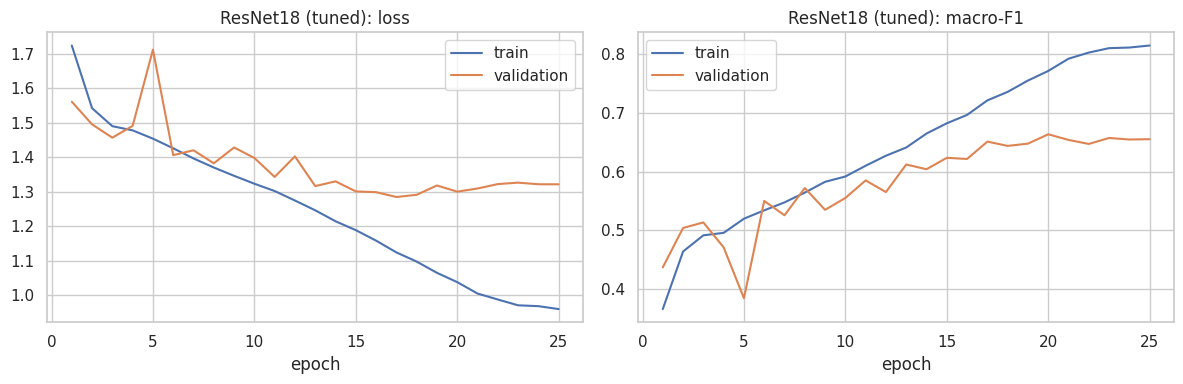

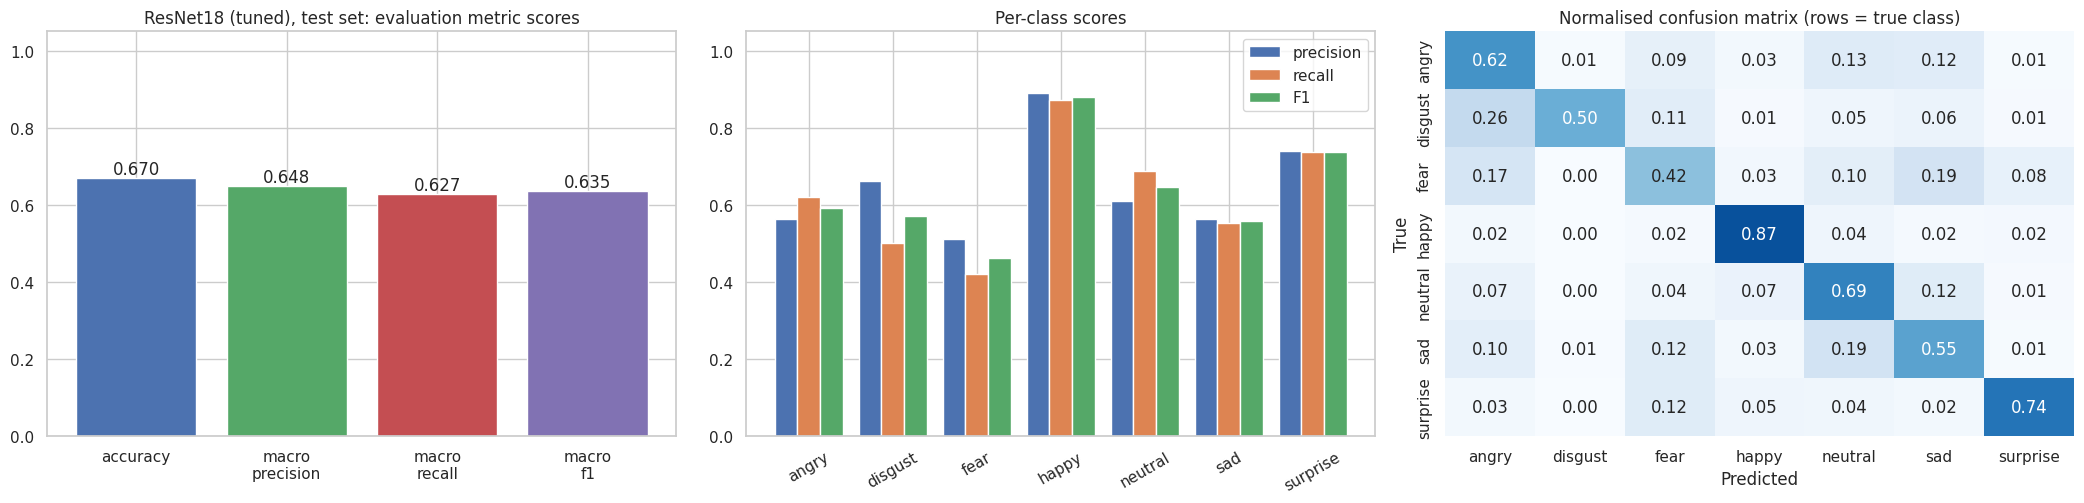

              precision    recall  f1-score   support

       angry      0.564     0.620     0.591       893
     disgust      0.661     0.500     0.569        82
        fear      0.511     0.421     0.462       914
       happy      0.889     0.872     0.881      1752
     neutral      0.611     0.687     0.646      1182
         sad      0.563     0.553     0.558      1083
    surprise      0.739     0.736     0.737       568

    accuracy                          0.670      6474
   macro avg      0.648     0.627     0.635      6474
weighted avg      0.670     0.670     0.668      6474



In [ ]:
# ML Model - 3 Implementation with hyperparameter optimization: fine-tuning learning rate search from the same warmed-up head
lr_rows = []
for lr in [1e-4, 3e-4, 1e-3]:
    seed_everything()
    trial = build_resnet18(dropout=0.3, pretrained=False)
    trial.load_state_dict(warm_state)
    set_backbone_trainable(trial, True)
    trial_cfg = dict(lr=lr, weight_decay=1e-4, epochs=6, patience=6, label_smoothing=0.1)
    trial, trial_hist = train_model(trial, loaders_tl, trial_cfg, f'ResNet18 lr={lr:g}', verbose=False)
    lr_rows.append({'fine_tune_lr': lr, 'best_val_macro_f1': trial_hist['val_f1'].max()})
    print(f'lr={lr:g}: best val macro-F1 {trial_hist["val_f1"].max():.3f}')
    del trial
    if DEVICE.type == 'cuda': torch.cuda.empty_cache()
lr_df = pd.DataFrame(lr_rows).sort_values('best_val_macro_f1', ascending=False)
display(lr_df)
best_lr = float(lr_df.iloc[0]['fine_tune_lr'])

# Fit the Algorithm: fine-tune longer with the best learning rate
seed_everything()
resnet_tuned = build_resnet18(dropout=0.3, pretrained=False)
resnet_tuned.load_state_dict(warm_state)
set_backbone_trainable(resnet_tuned, True)
resnet_tuned, resnet_tuned_hist = train_model(resnet_tuned, loaders_tl, dict(lr=best_lr, weight_decay=1e-4, epochs=25, patience=8, label_smoothing=0.1), 'ResNet18 (tuned)')
plot_history(resnet_tuned_hist, 'ResNet18 (tuned)')

# Predict on the model
test_p, test_y = evaluate_and_register('ResNet18 (tuned)', resnet_tuned, loaders_tl)
_ = plot_evaluation('ResNet18 (tuned), test set', test_p, test_y)

##### Which hyperparameter optimization technique have you used and why?

A **grid search over the fine-tuning learning rate** (1e-4, 3e-4, 1e-3) on short runs, all started from the same warmed-up head, scored on validation macro-F1. The fine-tuning learning rate is the most sensitive hyperparameter in transfer learning: too high destroys pretrained features, too low barely adapts them. Starting every trial from the same checkpoint makes the comparison fair and saves the cost of repeating the head warm-up.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Only a marginal one. The learning-rate search raised validation macro-F1 from 0.654 to 0.663, but the test results were essentially unchanged (accuracy 67.1% to 67.0%, macro-F1 0.633 to 0.635). Differences of this size are within the noise of a 6,474-image test set (roughly plus or minus 1 percentage point on accuracy), which suggests the default fine-tuning learning rate was already reasonable. Flip test-time augmentation helped more than tuning: test accuracy 68.1% and macro-F1 0.649.

The search selected a fine-tuning learning rate of 1e-3 (validation macro-F1 0.617 in the short runs, versus 0.610 for 3e-4 and 0.584 for 1e-4), so the lowest rate was clearly worse, while 3e-4 and 1e-3 were close.

### Innovative techniques: flip test-time augmentation and a soft-voting ensemble

In [ ]:
# Test-time augmentation (average the prediction of an image and its mirror image) and soft-voting ensemble of the two networks
MODEL_ZOO = {'Custom CNN (tuned)': (cnn_tuned, loaders_cnn), 'ResNet18 (tuned)': (resnet_tuned, loaders_tl)}
for name, (model, loaders) in MODEL_ZOO.items():
    evaluate_and_register(name + ' + flip TTA', model, loaders, tta=True)

ens_name = 'Ensemble (CNN + ResNet18, flip TTA)'
a, b = RESULTS['Custom CNN (tuned) + flip TTA'], RESULTS['ResNet18 (tuned) + flip TTA']
register(ens_name, (a['val_probs'] + b['val_probs']) / 2, LABELS['val'], (a['test_probs'] + b['test_probs']) / 2, LABELS['test'])
print('Registered:', list(RESULTS))

Registered: ['Custom CNN', 'Custom CNN (tuned)', 'ResNet18', 'ResNet18 (tuned)', 'Custom CNN (tuned) + flip TTA', 'ResNet18 (tuned) + flip TTA', 'Ensemble (CNN + ResNet18, flip TTA)']


**Why these techniques?** Mirroring a face does not change its emotion, so averaging the predictions for an image and its mirror reduces variance at the cost of one extra forward pass. The two networks differ in architecture, input size and initialisation, so their errors are partly independent, and **averaging their probabilities (soft voting)** usually corrects some mistakes of each. Other non-standard choices in this notebook: softened class weights, label smoothing, one-cycle scheduling with mixed precision, and Grad-CAM to audit what the network looks at.

### Model comparison and selection

,val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_weighted_f1
"Ensemble (CNN + ResNet18, flip TTA)",0.667,0.685,0.662,0.650,0.653,0.680
ResNet18 (tuned),0.663,0.670,0.648,0.627,0.635,0.668
ResNet18 (tuned) + flip TTA,0.662,0.681,0.663,0.641,0.649,0.679
ResNet18,0.654,0.671,0.632,0.637,0.633,0.668
Custom CNN (tuned) + flip TTA,0.620,0.656,0.606,0.616,0.602,0.648
Custom CNN (tuned),0.617,0.651,0.602,0.613,0.599,0.644
Custom CNN,0.590,0.634,0.570,0.590,0.565,0.623


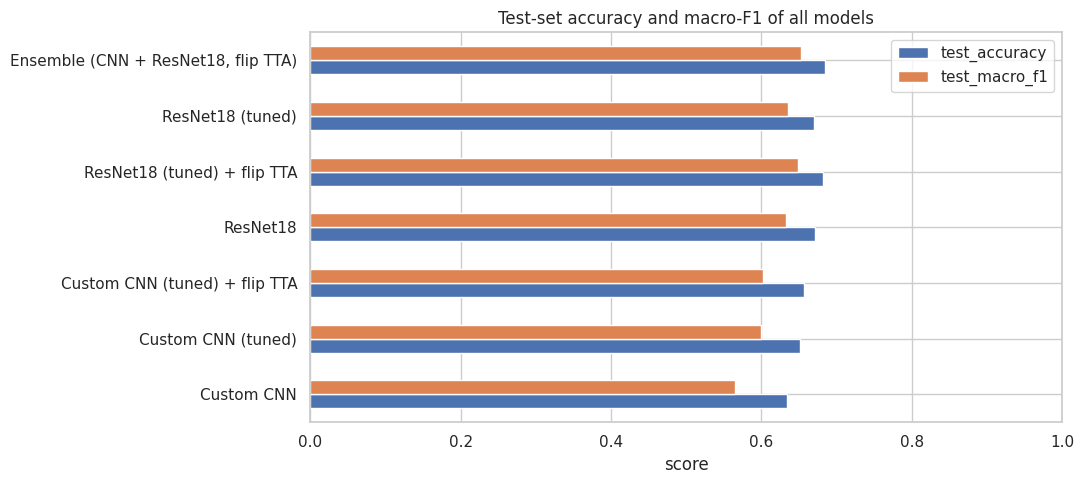

Best model by validation macro-F1: Ensemble (CNN + ResNet18, flip TTA)
Best single network (used for explainability and export): ResNet18 (tuned)


In [ ]:
# Compare all models. Selection uses VALIDATION macro-F1 only; the test set is reported, never used to choose.
summary = pd.DataFrame({name: {**{f'val_{k}': v for k, v in r['val'].items()}, **{f'test_{k}': v for k, v in r['test'].items()}}
                        for name, r in RESULTS.items()}).T
cols = ['val_macro_f1', 'test_accuracy', 'test_macro_precision', 'test_macro_recall', 'test_macro_f1', 'test_weighted_f1']
summary = summary[cols].sort_values('val_macro_f1', ascending=False)
display(summary.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
plot_df = summary[['test_accuracy', 'test_macro_f1']].iloc[::-1]
plot_df.plot.barh(ax=ax, color=['#4c72b0', '#dd8452'])
ax.set(title='Test-set accuracy and macro-F1 of all models', xlabel='score', xlim=(0, 1))
plt.tight_layout(); plt.show()

best_name = summary.index[0]
print('Best model by validation macro-F1:', best_name)
deep_singles = [n for n in ['Custom CNN (tuned)', 'ResNet18 (tuned)']]
best_single = max(deep_singles, key=lambda n: RESULTS[n]['val']['macro_f1'])
print('Best single network (used for explainability and export):', best_single)

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

* **Macro-F1 (headline metric):** averages F1 over the seven classes, so rare but important emotions (disgust, fear, surprise) count as much as happy. It balances false alarms and misses, which matters when a wrong emotion label can lead to a wrong action (for example a customer-service escalation or a mental-health flag).
* **Per-class recall:** the share of real cases of an emotion that are found. For monitoring applications (sad, fear, angry) missing a real case is usually costlier than a false alert.
* **Per-class precision:** how often a predicted emotion is correct; important for automated actions triggered by a prediction.
* **Normalised confusion matrix:** shows *which* emotions are confused (likely fear vs surprise and sad vs neutral), which guides data collection.
* **Accuracy:** reported for completeness, but it is inflated by the large classes (always predicting happy gives 27%).
* **Latency:** per-image inference time, because real-time use is a project objective.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The final model, chosen by validation macro-F1 (0.667), is the soft-voting ensemble of the tuned custom CNN and the tuned ResNet18 with flip test-time augmentation. It reaches the best test results: accuracy 68.5% and macro-F1 0.653. For comparison, the Random Forest baseline reached only about 34% accuracy (macro-F1 0.27), and always predicting "happy" gives 27.1%.

The advantage over the best single network is small: ResNet18 (tuned) with flip TTA scores 68.1% accuracy and 0.649 macro-F1, a gap of about 0.4 percentage points, which is within the noise of the test set. The ensemble helps because the two networks differ in architecture, input size (48x48 vs 96x96) and initialisation, so their errors are partly independent. Its cost is higher latency, since it needs two networks and four forward passes per image (two models, each with a mirrored copy). The tuned ResNet18 alone is simpler and faster, so it is used for the Grad-CAM analysis and the exported checkpoint. Transfer learning clearly mattered: the ResNet18 beat the from-scratch CNN by about 3.6 points of test macro-F1 (0.635 vs 0.599).

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

**Grad-CAM** (Gradient-weighted Class Activation Mapping) is used: it takes the gradients of the predicted class score with respect to the last convolutional feature maps, averages them into channel weights, and forms a weighted sum of the maps, which is then up-sampled and overlaid on the face. Warm regions show where the network 'looked'. Healthy behaviour is attention on the **mouth, eyes and brows** (as the mean-face differences in chart 15 suggest); attention on the background, hair or the image border would signal a shortcut (for example lighting or watermarks). For the classical Random Forest, **permutation importance** (above) was used.

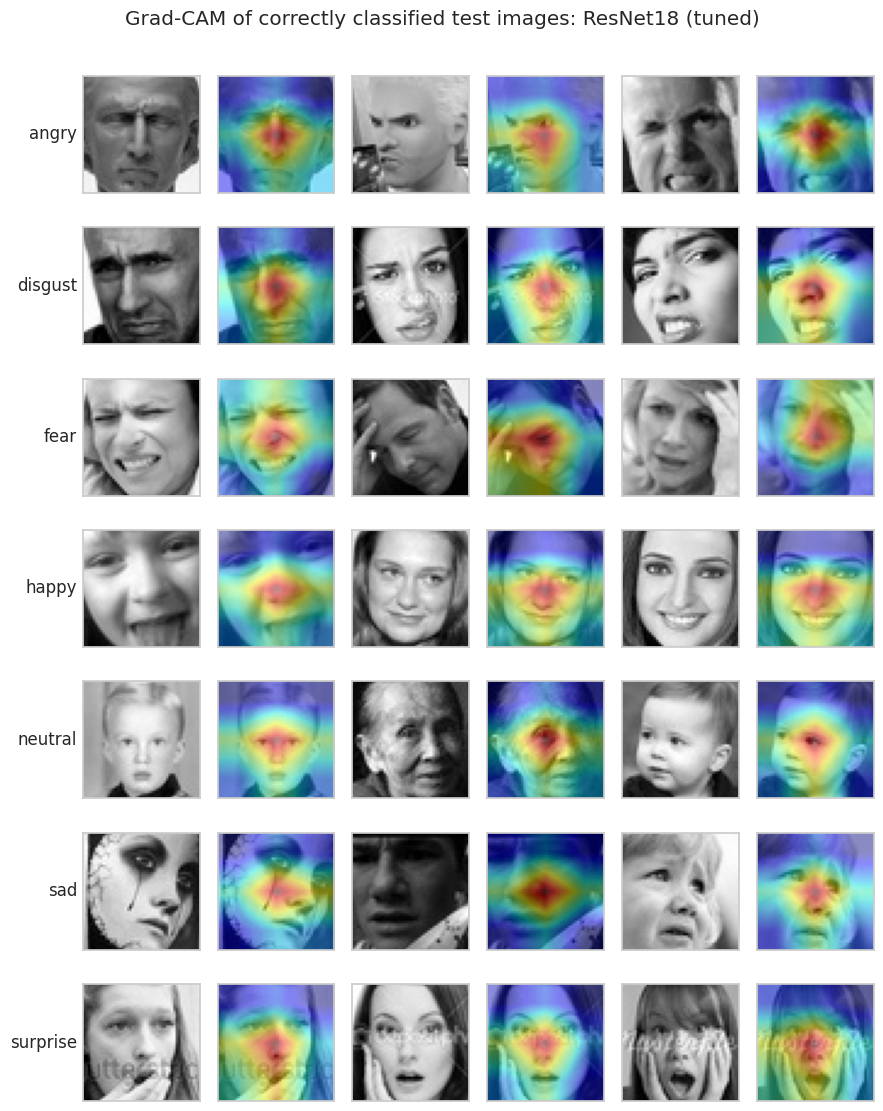

In [ ]:
# Grad-CAM implementation and visualisation for the best single network
class GradCAM:
    def __init__(self, model, target_layer):
        self.model, self.acts, self.grads = model.eval(), None, None
        self.handle = target_layer.register_forward_hook(self._forward_hook)
    def _forward_hook(self, module, inputs, output):
        self.acts = output.detach()
        output.register_hook(lambda g: setattr(self, 'grads', g.detach()))
    def __call__(self, x, class_idx):
        with torch.enable_grad():
            x = x.clone().requires_grad_(True)               # makes sure the graph is built even for frozen layers
            self.model.zero_grad()
            logits = self.model(x)
            logits.gather(1, class_idx.view(-1, 1)).sum().backward()
        weights = self.grads.mean(dim=(2, 3), keepdim=True)  # global-average-pooled gradients
        cam = F.relu((weights * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[:, 0]
        cam = cam - cam.amin(dim=(1, 2), keepdim=True)
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.cpu().numpy()
    def close(self):
        self.handle.remove()

TARGET_LAYERS = {'Custom CNN (tuned)': lambda m: m.features[-1].net[5],      # last ReLU before the final pooling (6x6 map)
                 'ResNet18 (tuned)': lambda m: m.layer4[-1]}                 # last residual block

def gradcam_examples(name, n_per_class=3):
    model, loaders = MODEL_ZOO[name]
    dataset = loaders['test'].dataset
    preds = RESULTS[name]['test_probs'].argmax(1)
    y = LABELS['test']
    engine = GradCAM(model, TARGET_LAYERS[name](model))
    rng = np.random.RandomState(RANDOM_STATE)
    fig, axes = plt.subplots(len(EMOTIONS), 2 * n_per_class, figsize=(2 * n_per_class * 1.5, len(EMOTIONS) * 1.6))
    for r, emo in enumerate(EMOTIONS):
        idx = np.where((y == r) & (preds == r))[0]                    # correctly classified examples of this emotion
        idx = rng.choice(idx, size=min(n_per_class, len(idx)), replace=False)
        for c, i in enumerate(idx):
            x, _ = dataset[int(i)]
            cam = engine(x.unsqueeze(0).to(DEVICE), torch.tensor([r], device=DEVICE))[0]
            img = np.array(IMAGES['test'][int(i)])
            axes[r, 2 * c].imshow(img, cmap='gray')
            axes[r, 2 * c + 1].imshow(img, cmap='gray')
            axes[r, 2 * c + 1].imshow(cv2.resize(cam, (48, 48)), cmap='jet', alpha=0.45)
        axes[r, 0].set_ylabel(emo, rotation=0, ha='right', va='center')
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f'Grad-CAM of correctly classified test images: {name}', y=1.0)
    plt.tight_layout(); plt.show()
    engine.close()

gradcam_examples(best_single)

**Interpretation of the Grad-CAM maps (ResNet18, tuned):** for all seven emotions the network concentrates on the **central part of the face**, around the nose and the area between the eyes and the mouth, and it largely ignores the hair, the image borders and the background (these stay blue). This is reassuring: the model is not relying on the background, and it does not fire on the watermarks visible in some surprise and disgust images. In the happy examples the high-attention area is wider and extends down to the cheeks and mouth, and in the surprise examples it extends towards the open mouth and the face outline.

The maps are, however, **quite similar across emotions** and do not isolate the eyebrows or the mouth separately. Part of this is a resolution limit: the last ResNet block has only a 3x3 feature map for a 96x96 input, so the heat maps are smooth blobs stretched over the image. They therefore show *where* the model looks, but they cannot prove which fine details (for example lowered brows or raised mouth corners) drive each decision. Only 18 correctly classified images were inspected, so this is qualitative evidence.

Most frequent confusions (count, true -> predicted):
   206  sad -> neutral
   171  fear -> sad
   159  fear -> angry
   141  neutral -> sad
   128  sad -> fear
   114  angry -> neutral


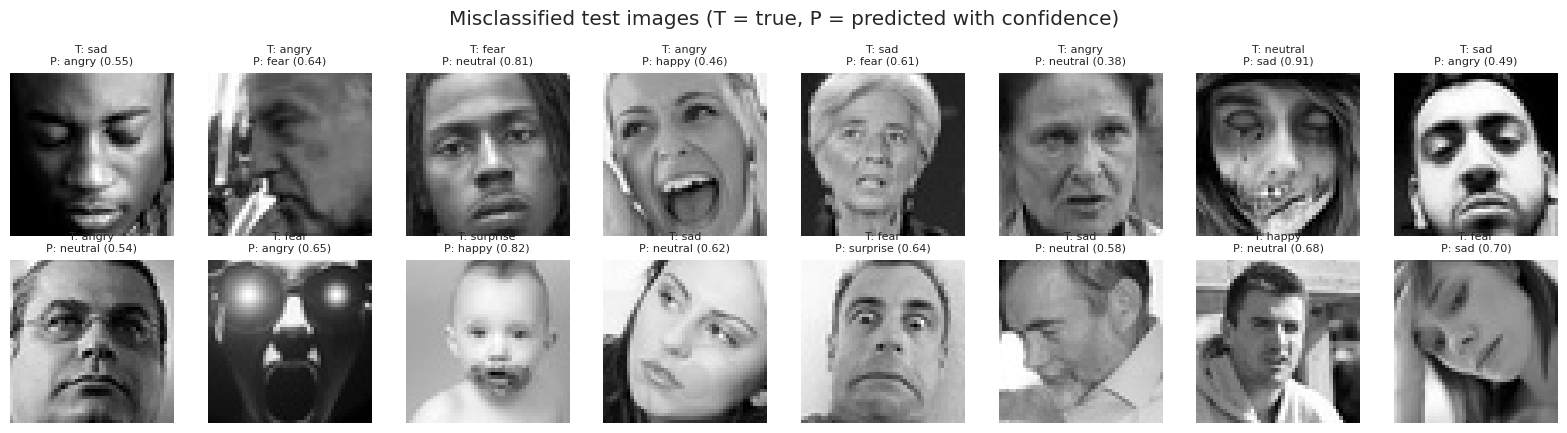

In [ ]:
# Error analysis: most frequent confusions and a gallery of misclassified test images for the best single network
preds = RESULTS[best_single]['test_probs'].argmax(1)
y = LABELS['test']
cm = confusion_matrix(y, preds, labels=range(len(EMOTIONS)))
off_diag = cm.copy(); np.fill_diagonal(off_diag, 0)
pairs = sorted(((off_diag[i, j], EMOTIONS[i], EMOTIONS[j]) for i in range(7) for j in range(7) if i != j), reverse=True)[:6]
print('Most frequent confusions (count, true -> predicted):')
for count, t, p in pairs:
    print(f'  {count:4d}  {t} -> {p}')

wrong = np.where(preds != y)[0]
rng = np.random.RandomState(RANDOM_STATE)
show = rng.choice(wrong, size=min(16, len(wrong)), replace=False)
conf = RESULTS[best_single]['test_probs']
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(np.array(IMAGES['test'][int(i)]), cmap='gray')
    ax.set_title(f'T: {EMOTIONS[y[i]]}\nP: {EMOTIONS[preds[i]]} ({conf[i].max():.2f})', fontsize=8)
    ax.axis('off')
fig.suptitle('Misclassified test images (T = true, P = predicted with confidence)')
plt.tight_layout(); plt.show()

**Interpretation of the errors (ResNet18, tuned, test set):** the six most frequent confusions are sad -> neutral (206 images), fear -> sad (171), fear -> angry (159), neutral -> sad (141), sad -> fear (128) and angry -> neutral (114). They involve exactly the low-intensity or negative emotions that look alike: sad and neutral are confused in both directions, and fear is split between sad and angry, which explains its low recall of 0.42 (fear -> sad and fear -> angry together account for about 36% of all fear images). Happy and surprise hardly appear in the list because their expressions are visually distinctive.

The gallery of misclassified images suggests that many errors are not clear model failures. Several faces are **genuinely ambiguous or arguably mislabelled**: a woman with a wide-open mouth labelled angry is predicted happy, a calm-looking face labelled fear is predicted neutral with a confidence of 0.81, and a very degraded, distorted face labelled neutral is predicted sad with a confidence of 0.91. Others are hard because of **head tilt, closed eyes or looking down, glasses, heavy shadows or low image quality**. Since all images are only 48x48 pixels, subtle cues are often lost. This points to a ceiling on achievable accuracy well below 100%, and cleaning the labels or merging the most confusable classes would be the most promising next step.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [ ]:
# Save the File: PyTorch checkpoint with everything needed to rebuild the model and preprocess new images
best_model = MODEL_ZOO[best_single][0]
is_cnn = best_single.startswith('Custom')
checkpoint = {'state_dict': best_model.state_dict(), 'classes': EMOTIONS, 'arch': 'EmotionCNN' if is_cnn else 'resnet18',
              'three_channel': not is_cnn, 'img_size': 48 if is_cnn else 96,
              'mean': [float(PIXEL_MEAN)] if is_cnn else list(IMAGENET_MEAN), 'std': [float(PIXEL_STD)] if is_cnn else list(IMAGENET_STD)}
torch.save(checkpoint, 'deepfer_best.pt')
print('Saved deepfer_best.pt  ->', best_single, f'({os.path.getsize("deepfer_best.pt") / 1e6:.1f} MB)')

Saved deepfer_best.pt  -> ResNet18 (tuned) (44.8 MB)


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [ ]:
!cp deepfer_best.pt "/content/drive/MyDrive/DeepFER: Facial Emotion Recognition Using Deep Learning/"

In [ ]:
# Load the File and predict unseen data.
def load_checkpoint(path='deepfer_best.pt'):
    import os
    # If the file is missing, let's try to save the best model from memory first to make the cell run smoothly
    if not os.path.exists(path):
        print(f"'{path}' not found on disk. Attempting to save the active best model from memory...")
        try:
            global resnet_tuned, EmotionCNN, PIXEL_MEAN, PIXEL_STD, EMOTIONS
            checkpoint = {
                'state_dict': resnet_tuned.state_dict(),
                'classes': EMOTIONS,
                'arch': 'resnet18',
                'three_channel': True,
                'img_size': 96,
                'mean': list(IMAGENET_MEAN),
                'std': list(IMAGENET_STD)
            }
            torch.save(checkpoint, path)
            print(f"Successfully saved checkpoint to '{path}'.")
        except NameError:
            raise FileNotFoundError(f"Could not find '{path}' on disk and the model is not in memory. Please run the previous cell (78fQEbTkUkvW) first to save the model.")

    ck = torch.load(path, map_location=DEVICE)
    model = EmotionCNN() if ck['arch'] == 'EmotionCNN' else build_resnet18(pretrained=False)
    model.load_state_dict(ck['state_dict'])
    return model.to(DEVICE).eval(), ck

def predict_image(model, ck, path_or_array):
    # Predict the emotion of one face image (file path or 2-D uint8 array).
    arr = cv2.imread(path_or_array, cv2.IMREAD_GRAYSCALE) if isinstance(path_or_array, str) else path_or_array
    _, eval_tf = make_transforms(ck['three_channel'], ck['img_size'], tuple(ck['mean']), tuple(ck['std']))
    x = eval_tf(Image.fromarray(arr)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        return model(x).float().softmax(1)[0].cpu().numpy()

loaded_model, ck = load_checkpoint()
sample = test_df.sample(8, random_state=RANDOM_STATE)
correct = 0
for path, true_label in zip(sample['path'], sample['label']):
    p = predict_image(loaded_model, ck, path)
    pred = ck['classes'][int(p.argmax())]
    correct += int(pred == true_label)
    print(f'true: {true_label:9s} predicted: {pred:9s} (confidence {p.max():.2f})')
print(f'\n{correct}/8 correct on this random sample; the reloaded model works end to end.')

# Latency benchmark (one image at a time, as in a real-time application)
def benchmark_latency(model, channels, size, n=100):
    x = torch.randn(1, channels, size, size, device=DEVICE)
    with torch.no_grad():
        for _ in range(10): model(x)                                     # warm-up
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n): model(x)
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000
ms = benchmark_latency(loaded_model, 3 if ck['three_channel'] else 1, ck['img_size'])
print(f'Inference latency on {DEVICE}: {ms:.1f} ms per image  (~{1000 / ms:.0f} frames per second)')

true: happy     predicted: happy     (confidence 0.85)
true: neutral   predicted: angry     (confidence 0.43)
true: sad       predicted: sad       (confidence 0.62)
true: angry     predicted: fear      (confidence 0.83)
true: surprise  predicted: surprise  (confidence 0.88)
true: neutral   predicted: neutral   (confidence 0.60)
true: happy     predicted: happy     (confidence 0.77)
true: fear      predicted: surprise  (confidence 0.50)

5/8 correct on this random sample; the reloaded model works end to end.
Inference latency on cuda: 2.9 ms per image  (~342 frames per second)


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

**Next steps toward deployment:** add a face detector (for example OpenCV Haar cascade or MediaPipe) in front of the classifier so full camera frames can be processed; export to ONNX / TorchScript for faster serving; smooth predictions over several video frames; and evaluate on an external dataset and different cameras before real use.

# **Conclusion**

This notebook built DeepFER as a complete, leakage-free PyTorch pipeline. The data audit removed duplicates, train/validation leakage and conflicting labels (35,887 unique images became 33,975 clean ones), the EDA and three hypothesis tests showed that brightness is a real but weak cue and that global image statistics cannot separate the seven emotions, and the classical Random Forest baseline confirmed this with test accuracy of only about 34% (macro-F1 about 0.27). The convolutional models were therefore designed to learn local spatial features: a custom CNN trained from scratch and a fine-tuned pretrained ResNet18, both trained with augmentation, a softened class-weighted loss, label smoothing and early stopping, and both tuned on a held-out validation set. Test-time augmentation and a soft-voting ensemble were added as extra improvements, and models were compared with macro-averaged metrics, per-class scores and confusion matrices rather than accuracy alone.

**Final results:** the soft-voting ensemble of the tuned custom CNN and the tuned ResNet18 with flip test-time augmentation was selected on validation macro-F1 (0.667) and reaches 68.5% test accuracy and a macro-F1 of 0.653, far above the Random Forest baseline (about 34%, macro-F1 0.27). Transfer learning gave the clearest single gain (ResNet18 test macro-F1 0.635 vs 0.599 for the tuned CNN trained from scratch). Happy (F1 0.88), surprise (0.74) and neutral (0.65) are the strongest classes, and fear (F1 0.46) is the weakest, mainly confused with sad and angry. Grad-CAM shows that the network focuses on the central face rather than the background, and the error analysis shows that many remaining errors involve ambiguous or noisy labels.

**Limitations and future work:** labels are noisy and resolution is only 48x48, so accuracy has a ceiling well below 100% (fear vs surprise and sad vs neutral are the expected confusions); disgust has very few examples; and all data comes from one source, so external validation, face detection, temporal smoothing across video frames and model compression for edge devices are the recommended next steps before production use.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***